# Local projections
Delspørgsmål 1 (EUR/USD) og 3 (USD-hedge ratio) estimeres med **samme** LP-funktion.

**Rækkefølge:** 1 opsætning → 2 data og variable → 3 deskriptivt → 4 funktioner → 5 horisonter og lag-valg → 6 EUR/USD → 7 EUR/USD robusthed → 8 EUR/USD bootstrap → 9 hedge ratio → 10 bootstrap af bruddet (EUR/USD og hedge ratio) → 11 diagnostik

Kør altid hele notebooken fra toppen ("Restart & Run All"). Bootstrap-cellerne (B = 999) tager tid; test evt. først med B = 99.

## 1. Opsætning

In [ ]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, NullFormatter
from scipy.stats import norm, skew
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, acorr_ljungbox
from IPython.display import display

BASE = "/Users/PC/Documents/Speciale/Analyse/Speciale"     # mappen med 'clean'
MASTER = os.path.join(BASE, "clean", "master_monthly.csv")
FIG_DIR, TAB_DIR = "FIGURES", "TABLES"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

BLAA, BLAA_LYS, ROED = "#1f3864", "#5b9bd5", "#b22222"
z68, z95 = norm.ppf(0.84), norm.ppf(0.975)

VIS_TABELLER = True    # False = drop de lange tabeller i notebooken (LaTeX-filerne gemmes stadig)
KOER_LAGVALG = True   # True = vis informationskriterier for lag-valget (afsnit 5)

## 2. Data og variable

In [ ]:
master = pd.read_csv(MASTER, parse_dates=["month"]).sort_values("month").reset_index(drop=True)
print("Master:", master.shape, "|", master["month"].min().date(), "->", master["month"].max().date())
print("Manglende værdier (forventet: basis swap før 2021, CRSP efter 2025, toldsats sep. 2026, "
      "EUR_afd_usd/ovr):\n", master.isna().sum()[lambda s: s > 0])

Master: (141, 51) | 2015-01-31 -> 2026-09-30
Manglende værdier (forventet: basis swap før 2021, CRSP efter 2025, toldsats sep. 2026, EUR_afd_usd/ovr):
 EURUSD basis swap 3m    73
vwretd                   9
bond_ret                 9
EUR_afd_usd              5
EUR_afd_ovr              5
toldsats                 1
dtype: int64


In [ ]:
# ---------- Stød: log og standardisering (1 enhed = 1 standardafvigelse) ----------
for v in ["TPU", "GPR", "GPRC_USA", "VIXCLS"]:
    master[f"ln{v}"] = np.log(master[v])
    master[f"ln{v}_z"] = (master[f"ln{v}"] - master[f"ln{v}"].mean()) / master[f"ln{v}"].std()

# ---------- Basiskontroller (stationære); inflation er beregnet i databehandlingen ----------
master["ip_growth"]  = 100 * np.log(master["INDPRO"]).diff()
master["nfp_growth"] = 100 * np.log(master["PAYEMS"]).diff()
master["d_DGS10"]    = master["DGS10"].diff()

# ---------- Delspørgsmål 1: dollarstyrke i pct. (+ = dollaren styrkes over for euroen) ----------
master["lnUSD"]  = -100 * np.log(master["EURUSD"])          # kurs ved månedens udgang (baseline)
master["dlnUSD"] = master["lnUSD"].diff()
master["lnUSD_bred"] = 100 * np.log(master["DTWEXBGS"])     # robusthed: Fed's brede dollarindeks
master["lnUSD_gns"]  = -100 * np.log(master["EURUSD_gns"])  # robusthed: EUR/USD som månedsgennemsnit

# ---------- Delspørgsmål 3: USD-hedge ratio (pp.) og dens to komponenter (log-pct.) ----------
master["hr"]      = 100 * master["USD_hedge_ratio"]
master["ln_afd"]  = 100 * np.log(master["USD_afd_total"])   # afdækket beløb (aktiv afdækning)
master["ln_eksp"] = 100 * np.log(master["USD_eksp_total"])  # samlet eksponering (værdiregulering)

# ---------- Ekstra kontroller (robusthed) ----------
master["d_ois_spread"] = (master["USD OIS 3m"] - master["EUR OIS 3m"]).diff()  # relativ pengepolitik
master["d_toldsats"]   = master["toldsats"].diff()             # ændring i effektiv toldsats, pp.
master["spxt_ret"]     = 100 * np.log(master["SPXT"]).diff()   # aktieafkast (erstatter vwretd, der slutter 2025)
# 'covid' (1 i marts–juni 2020) er lavet i databehandlingen

# ---------- Brud ----------
master["post_LD"] = (master["month"] >= "2025-04-30").astype(int)   # Liberation Day (april 2025)
master["post_RU"] = (master["month"] >= "2022-02-28").astype(int)   # Ruslands invasion (feb. 2022)

# ---------- Fælles konstanter ----------
BASIS_KONTROLLER = ("ip_growth", "nfp_growth", "inflation", "d_DGS10")
N_LAGS = 2          # baseline antal lags (Ljung-Box, jf. afsnit 11)
VIX = "lnVIXCLS_z"

# (stød, navn i figurer, navn i LaTeX, kort navn til filer)
STOED = [("lnTPU_z",      "TPU",           "TPU",                         "tpu"),
         ("lnGPR_z",      "GPR",           "GPR",                         "gpr"),
         ("lnGPRC_USA_z", "GPR$_{USA}$",   r"$\text{GPR}_{\text{USA}}$",  "gpr_usa")]

# Episoder, der udelades i robusthed (stødmåneder). GPR-episoderne følger reglen z > 2, jf. afsnit 3
EPISODER_TPU_LP = [("2018-01-31", "2019-12-31"),   # handelskrigen 2018–2019
                   ("2025-01-31", "2025-12-31")]   # 2025 (bruges kun, når stikprøven går ud over 2024)
EPISODER_GPR_LP = [("2022-02-28", "2022-03-31"),   # Ruslands invasion af Ukraine
                   ("2025-06-30", "2025-06-30"),   # krigen mellem Israel og Iran
                   ("2026-03-31", "2026-04-30")]   # krigen mellem USA og Iran

## 3. Deskriptivt (til data- og metodeafsnittet)

In [ ]:
# ---------- Persistens: AR(1)-koefficient ----------
for v in ["lnTPU", "lnGPR", "lnGPRC_USA", "hr", "toldsats"]:
    tmp = master.assign(lag=master[v].shift(1)).dropna(subset=[v, "lag"])
    phi = smf.ols(f"{v} ~ lag", data=tmp).fit().params["lag"]
    print(f"{v}: phi = {phi:.3f}")

lnTPU: phi = 0.920
lnGPR: phi = 0.724
lnGPRC_USA: phi = 0.712
hr: phi = 0.918
toldsats: phi = 0.988


In [ ]:
# ---------- Højeste måneder og episoder efter reglen z > 2 ----------
def z_episoder(kol, graense=2.0):
    """Sammenhængende måneder, hvor det standardiserede log-indeks er over graense."""
    s = np.log(master.set_index("month")[kol])
    z = (s - s.mean()) / s.std()
    ep, start, forrige = [], None, None
    for m in z[z > graense].index.to_period("M"):
        if start is not None and m == forrige + 1:
            forrige = m
        else:
            if start is not None:
                ep.append((start, forrige))
            start = forrige = m
    if start is not None:
        ep.append((start, forrige))
    return [(a.to_timestamp(how="end").strftime("%Y-%m-%d"),
             b.to_timestamp(how="end").strftime("%Y-%m-%d")) for a, b in ep]

for kol in ["GPR", "GPRC_USA", "TPU"]:
    s = master.set_index("month")[kol]
    z = (np.log(s) - np.log(s).mean()) / np.log(s).std()
    print(f"\n===== {kol}: 10 højeste måneder =====")
    print(pd.DataFrame({"værdi": s.round(0), "z": z.round(2)})
          .sort_values("værdi", ascending=False).head(10))
    print("Episoder med z > 2:", z_episoder(kol))

# Tjek at de episoder, der udelades i robusthed, stadig følger reglen med de opdaterede data
if z_episoder("GPR") != EPISODER_GPR_LP:
    print("\nOBS: EPISODER_GPR_LP afviger fra reglen z > 2 for GPR. Ret listen i afsnit 2 eller teksten.")
    print("Regel:", z_episoder("GPR"), "\nListe:", EPISODER_GPR_LP)


===== GPR: 10 højeste måneder =====
            værdi     z
month                  
2026-03-31  330.0  3.53
2022-03-31  319.0  3.42
2026-04-30  248.0  2.62
2025-06-30  222.0  2.26
2022-02-28  216.0  2.17
2026-05-31  202.0  1.96
2023-10-31  198.0  1.89
2022-04-30  191.0  1.78
2026-06-30  178.0  1.55
2025-03-31  176.0  1.51
Episoder med z > 2: [('2022-02-28', '2022-03-31'), ('2025-06-30', '2025-06-30'), ('2026-03-31', '2026-04-30')]

===== GPRC_USA: 10 højeste måneder =====
            værdi     z
month                  
2026-03-31    9.0  3.55
2026-04-30    7.0  2.75
2022-03-31    7.0  2.88
2025-06-30    6.0  2.30
2026-01-31    5.0  1.66
2025-03-31    5.0  1.63
2026-06-30    5.0  1.69
2026-05-31    5.0  2.09
2022-02-28    5.0  1.86
2023-10-31    4.0  1.58
Episoder med z > 2: [('2022-03-31', '2022-03-31'), ('2025-06-30', '2025-06-30'), ('2026-03-31', '2026-05-31')]

===== TPU: 10 højeste måneder =====
             værdi     z
month                   
2025-04-30  1151.0  3.07
2025-05-31 

In [ ]:
# ---------- TPU og den effektive toldsats ----------
d = master[["lnTPU", "toldsats", "d_toldsats"]].copy()
d["d_lnTPU"] = d["lnTPU"].diff()
print("Korrelation, niveauer (log TPU og toldsats):", round(d[["lnTPU", "toldsats"]].corr().iloc[0, 1], 3))
print("Korrelation, månedlige ændringer:           ", round(d[["d_lnTPU", "d_toldsats"]].corr().iloc[0, 1], 3))

# ---------- EUR/USD som mål for dollaren over for kronen ----------
d_fx = master[["month", "EURUSD", "USDDKK"]].dropna().copy()
d_fx["usd_eur"] = 100 * np.log(1 / d_fx["EURUSD"]).diff()
d_fx["usd_dkk"] = 100 * np.log(d_fx["USDDKK"]).diff()
print("\nKorrelation USD/EUR og USD/DKK, ændringer:", round(d_fx[["usd_eur", "usd_dkk"]].corr().iloc[0, 1], 3))
print("Korrelation, niveauer:                    ", round(np.corrcoef(1 / d_fx["EURUSD"], d_fx["USDDKK"])[0, 1], 3))
print("Std.afv. af EUR/DKK-ændringer (pct.):     ", round((d_fx["usd_dkk"] - d_fx["usd_eur"]).std(), 3))

# ---------- Sammensætning af den afdækkede USD-eksponering (første og sidste måned) ----------
u = master.dropna(subset=["USD_afd_total"])
for k in ["USD_afd_dkk", "USD_afd_eur", "USD_afd_usd", "USD_afd_ovr"]:
    print(k, "andel af afdækket:", (u[k] / u["USD_afd_total"]).iloc[[0, -1]].round(2).tolist())

Korrelation, niveauer (log TPU og toldsats): 0.654
Korrelation, månedlige ændringer:            0.126

Korrelation USD/EUR og USD/DKK, ændringer: 1.0
Korrelation, niveauer:                     0.999
Std.afv. af EUR/DKK-ændringer (pct.):      0.059
USD_afd_dkk andel af afdækket: [0.75, 0.28]
USD_afd_eur andel af afdækket: [0.25, 0.7]
USD_afd_usd andel af afdækket: [0.0, 0.0]
USD_afd_ovr andel af afdækket: [0.0, 0.02]


### Figurer: TPU, toldsats og GPR

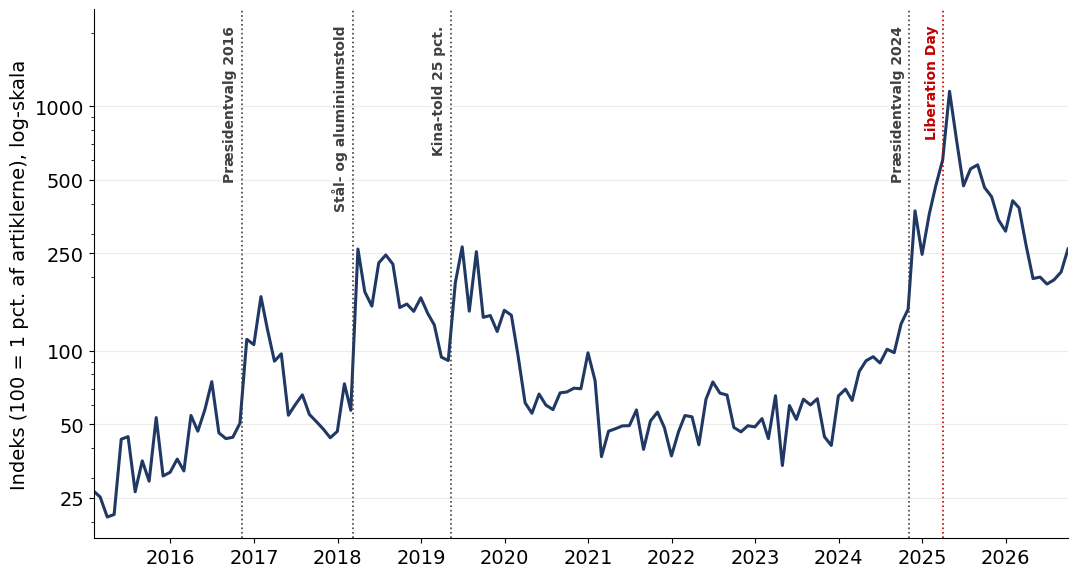

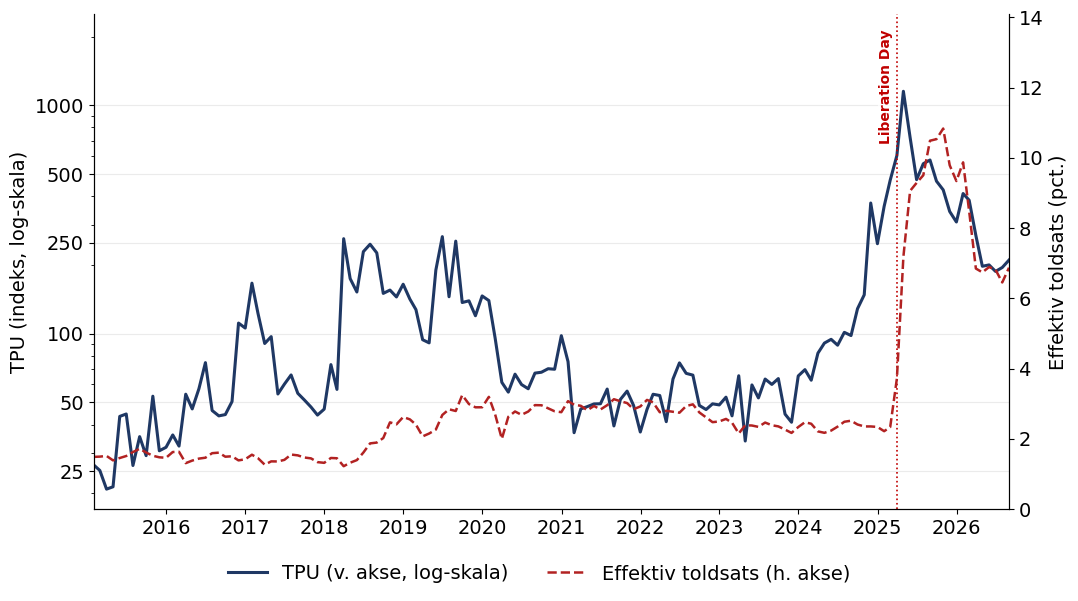

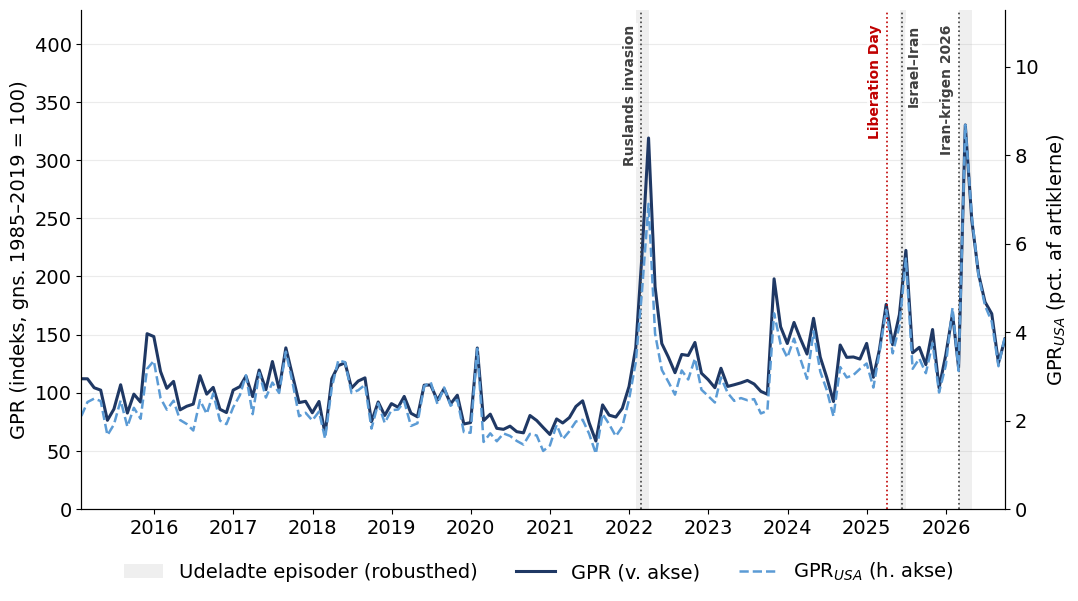

In [ ]:
offset = pd.Timedelta(days=20)

def marker(ax, dato, tekst, farve="#404040", side="h"):
    """Stiplet linje med lodret tekst. side='h': tekst til højre for linjen, 'v': til venstre."""
    x = pd.Timestamp(dato)
    ax.axvline(x, color=farve, lw=1.2, ls=":")
    ax.text(x + (offset if side == "h" else -offset), 0.97, tekst,
            color=farve, fontsize=10, fontweight="semibold", rotation=90, va="top",
            ha="left" if side == "h" else "right",
            transform=ax.get_xaxis_transform(), zorder=5,
            bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))

def x_akse(ax, data):
    """Årstal på x-aksen og grænser fra første til sidste måned med data."""
    ax.set_xlim(data["month"].min(), data["month"].max())
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.spines["top"].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

def log_akse(ax, ticks=(25, 50, 100, 250, 500, 1000)):
    ax.set_yscale("log")
    ax.set_yticks(list(ticks))
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())

with plt.rc_context({"font.size": 14}):

    # ---------- Figur: TPU ----------
    LOG_TPU = True   # logaritmisk y-akse (som Caldara et al. 2020, figur 3)
    dt = master.dropna(subset=["TPU"])
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(dt["month"], dt["TPU"], color=BLAA, lw=2.2, label="TPU")
    if LOG_TPU:
        log_akse(ax)
    ax.set_ylabel("Indeks (100 = 1 pct. af artiklerne)" + (", log-skala" if LOG_TPU else ""))
    ax.spines["right"].set_visible(False)
    ax.set_ylim(top=2500 if LOG_TPU else dt["TPU"].max() * 1.4)
    for dato, tekst in [("2016-11-08", "Præsidentvalg 2016"), ("2018-03-08", "Stål- og aluminiumstold"),
                        ("2019-05-10", "Kina-told 25 pct."),  ("2024-11-05", "Præsidentvalg 2024")]:
        marker(ax, dato, tekst, side="v")
    marker(ax, "2025-04-02", "Liberation Day", farve="#c00000", side="v")
    x_akse(ax, dt)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "TPU.pdf"), bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, "TPU.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # ---------- Figur: TPU (v. akse) og effektiv toldsats (h. akse) ----------
    dtt = master.dropna(subset=["TPU", "toldsats"])
    fig, ax1 = plt.subplots(figsize=(11, 6))
    ax1.plot(dtt["month"], dtt["TPU"], color=BLAA, lw=2.2, label="TPU (v. akse, log-skala)")
    log_akse(ax1)
    ax1.set_ylim(top=2500)
    ax1.set_ylabel("TPU (indeks, log-skala)")
    ax2 = ax1.twinx()
    ax2.plot(dtt["month"], dtt["toldsats"], color=ROED, lw=1.8, ls="--", label="Effektiv toldsats (h. akse)")
    ax2.set_ylabel("Effektiv toldsats (pct.)")
    ax2.set_ylim(0, dtt["toldsats"].max() * 1.3)
    ax2.spines["top"].set_visible(False)
    marker(ax1, "2025-04-02", "Liberation Day", farve="#c00000", side="v")
    x_akse(ax1, dtt)
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.savefig(os.path.join(FIG_DIR, "TPU_toldsats.pdf"), bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, "TPU_toldsats.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # ---------- Figur: GPR (v. akse) og GPR_USA (h. akse) ----------
    VIS_EPISODER = True   # grå felter = de episoder, der udelades i robusthed
    dg = master.dropna(subset=["GPR", "GPRC_USA"])
    fig, ax1 = plt.subplots(figsize=(11, 6))
    if VIS_EPISODER:
        for i, (a, b) in enumerate(EPISODER_GPR_LP):
            ax1.axvspan(pd.Timestamp(a) - pd.offsets.MonthBegin(1), pd.Timestamp(b),
                        color="gray", alpha=0.12, lw=0,
                        label="Udeladte episoder (robusthed)" if i == 0 else None)
    ax1.plot(dg["month"], dg["GPR"], color=BLAA, lw=2.2, label="GPR (v. akse)")
    ax1.set_ylabel("GPR (indeks, gns. 1985–2019 = 100)")
    ax1.set_ylim(0, dg["GPR"].max() * 1.3)
    ax2 = ax1.twinx()
    ax2.plot(dg["month"], dg["GPRC_USA"], color=BLAA_LYS, lw=1.8, ls="--", label=r"GPR$_{USA}$ (h. akse)")
    ax2.set_ylabel(r"GPR$_{USA}$ (pct. af artiklerne)")
    ax2.set_ylim(0, dg["GPRC_USA"].max() * 1.3)
    ax2.spines["top"].set_visible(False)
    for dato, tekst, side in [("2022-02-24", "Ruslands invasion", "v"),
                              ("2025-06-13", "Israel–Iran",       "h"),
                              ("2026-02-28", "Iran-krigen 2026",  "v")]:
        marker(ax1, dato, tekst, side=side)
    marker(ax1, "2025-04-02", "Liberation Day", farve="#c00000", side="v")
    x_akse(ax1, dg)
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.savefig(os.path.join(FIG_DIR, "GPR.pdf"), bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, "GPR.png"), dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
# ---------- Figur: USD-eksponering, afdækket vs. uafdækket, med hedge ratio ----------
# Efterligner Nationalbankens figur (stablet areal + linje på højre akse)
dh_fig = master.dropna(subset=["USD_hedge_ratio", "USD_afd_total", "USD_uafd_total", "USD_eksp_total"]).copy()
dh_fig["hr_pct"] = dh_fig["USD_hedge_ratio"] * 100

for col, navn in [("USD_afd_total", "Afdækket USD-eksponering"),
                  ("USD_uafd_total", "Uafdækket USD-eksponering"),
                  ("hr_pct", "Hedge ratio (%)")]:
    print(f"{navn}: start ({dh_fig['month'].iloc[0].date()}) = {dh_fig[col].iloc[0]:.1f}   "
          f"slut ({dh_fig['month'].iloc[-1].date()}) = {dh_fig[col].iloc[-1]:.1f}")

with plt.rc_context({"font.size": 14}):
    fig, ax1 = plt.subplots(figsize=(11, 6))
    ax1.stackplot(dh_fig["month"], dh_fig["USD_afd_total"], dh_fig["USD_uafd_total"],
                  labels=["Afdækket USD-eksponering", "Uafdækket USD-eksponering"],
                  colors=["#595959", "white"], edgecolor="black", linewidth=0.3)
    ax1.set_ylabel("Mia. kr. (USD-eksponering)")
    ax1.set_ylim(0, dh_fig["USD_eksp_total"].max() * 1.15)

    ax2 = ax1.twinx()
    ax2.plot(dh_fig["month"], dh_fig["hr_pct"], color="#b5314f", lw=2.5, label="USD-hedge ratio (h. akse)")
    ax2.set_ylabel("Pct.")
    ax2.set_ylim(0, 100)
    ax2.spines["top"].set_visible(False)

    marker(ax1, "2022-02-24", "Ruslands invasion", side="h")
    marker(ax1, "2025-04-02", "Liberation Day", farve="#c00000", side="v")
    x_akse(ax1, dh_fig)

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.savefig(os.path.join(FIG_DIR, "NB_Hedgingratio.pdf"), bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, "NB_Hedgingratio.png"), dpi=300, bbox_inches="tight")
    plt.show()

## 4. Funktioner
### 4a. Local projection, sammenligning og lag-valg

In [ ]:
def lp(data, y, shock, H=24, n_lags=N_LAGS,
       controls=BASIS_KONTROLLER, extra_controls=(), samtidige=(),
       shock_lags=True, y_lags=True,
       slut=None, dummy=None, ekskluder=None,
       se="hc3", fast_stikproeve=False, niveau=False):
    """Lag-augmenteret long-difference local projection.
    Venstreside: y(t+h) - y(t-1)   (Jordà & Taylor 2025, lign. 12)
    Højreside:   stød(t) + lags 1..n_lags af stød, Δy og alle kontroller
                 (lag-augmentation, Montiel Olea & Plagborg-Møller 2021)
    extra_controls: ekstra kontroller, der indgår med lags (robusthed)
    samtidige:      variable, der indgår samtidigt (bevidste tjek, fx covid-dummy)
    dummy:          brud-dummy; giver stød, dummy og stød × dummy (interaktionen phi_h)
    ekskluder:      liste af (fra, til); de stødmåneder udelades
    se:             'hc3' (baseline), 'hc1' eller 'nw' (Newey-West med h lags)
    niveau:         True = lags af y i niveau i stedet for Δy"""
    d = data.sort_values("month").reset_index(drop=True).copy()
    if slut is not None:
        d = d[d["month"] <= pd.Timestamp(slut)].reset_index(drop=True)

    d["_dy"] = d[y].diff()
    kilder = list(controls) + list(extra_controls)
    if y_lags:
        kilder.append(y if niveau else "_dy")
    if shock_lags:
        kilder.append(shock)

    lag_cols = []
    for v in kilder:
        for L in range(1, n_lags + 1):
            d[f"{v}_L{L}"] = d[v].shift(L)
            lag_cols.append(f"{v}_L{L}")

    X_cols = [shock] + list(samtidige) + lag_cols
    if dummy is not None:
        d["_int"] = d[shock] * d[dummy]
        X_cols += [dummy, "_int"]

    behold = pd.Series(True, index=d.index)
    if ekskluder is not None:
        for a, b in ekskluder:
            behold &= ~d["month"].between(pd.Timestamp(a), pd.Timestamp(b))
    if fast_stikproeve:
        behold &= d[y].shift(-H).notna()

    rows = []
    for h in range(H + 1):
        d["_lhs"] = d[y].shift(-h) - d[y].shift(1)
        sub = d.loc[behold, ["_lhs"] + X_cols].dropna()
        n_post = int(sub[dummy].sum()) if dummy is not None else None
        if dummy is not None and n_post < 3:          # for få observationer efter bruddet
            break
        mod = sm.OLS(sub["_lhs"], sm.add_constant(sub[X_cols]))
        m = (mod.fit(cov_type="HAC", cov_kwds={"maxlags": h}) if se == "nw"
             else mod.fit(cov_type=se.upper()))
        r = {"h": h, "coef": m.params[shock], "se": m.bse[shock],
             "p": m.pvalues[shock], "n": int(m.nobs)}
        if dummy is not None:                         # respons efter bruddet = beta_h + phi_h
            V = m.cov_params()
            b_post = m.params[shock] + m.params["_int"]
            se_post = np.sqrt(V.loc[shock, shock] + V.loc["_int", "_int"] + 2 * V.loc[shock, "_int"])
            r.update({"coef_int": m.params["_int"], "se_int": m.bse["_int"],
                      "p_int": m.pvalues["_int"],
                      "coef_post": b_post, "se_post": se_post,
                      "p_post": 2 * (1 - norm.cdf(abs(b_post / se_post))),
                      "n_post": n_post})
        rows.append(r)
    return pd.DataFrame(rows)


def sammenlign(specs, horisonter=(0, 3, 6, 12, 18, 24), kol="coef", pkol="p"):
    """specs: {navn: resultat fra lp()} -> (tabel med 'coef (p)', tabel med n)."""
    tab, nn = {}, {}
    for navn, res in specs.items():
        r = res.set_index("h").reindex(horisonter)
        tab[navn] = [f"{c:.2f} ({p:.3f})" if pd.notna(c) else "–" for c, p in zip(r[kol], r[pkol])]
        nn[navn] = r["n"].tolist()
    return pd.DataFrame(tab, index=horisonter).T, pd.DataFrame(nn, index=horisonter).T


def vaelg_lags(data, y, shock, pmax=6, controls=BASIS_KONTROLLER):
    """AIC, HQ og BIC for h=0-ligningen med 1..pmax lags (Jordà & Taylor 2025, s. 65)
    samt Breusch-Godfrey-test. Samme stikprøve for alle p, så kriterierne kan sammenlignes."""
    d = data.sort_values("month").reset_index(drop=True).copy()
    d["_dy"] = d[y].diff()
    kilder = list(controls) + ["_dy", shock]
    for v in kilder:
        for L in range(1, pmax + 1):
            d[f"{v}_L{L}"] = d[v].shift(L)
    d["_lhs"] = d[y] - d[y].shift(1)
    alle = ["_lhs", shock] + [f"{v}_L{L}" for v in kilder for L in range(1, pmax + 1)]
    sub = d[alle].dropna()
    T, ud = len(sub), []
    for p in range(1, pmax + 1):
        X = sm.add_constant(sub[[shock] + [f"{v}_L{L}" for v in kilder for L in range(1, p + 1)]])
        m = sm.OLS(sub["_lhs"], X).fit()
        k = X.shape[1]
        ud.append({"p": p, "AIC": m.aic, "HQ": -2 * m.llf + 2 * k * np.log(np.log(T)),
                   "BIC": m.bic, "BG_p (12 lags)": acorr_breusch_godfrey(m, nlags=12)[1]})
    return pd.DataFrame(ud).set_index("p")

### 4b. Figurer

In [ ]:
YL_USD = "Pct. (+ = dollaren styrkes over for euroen)"
YL_HR  = "Procentpoint (+ = højere USD-hedge ratio)"

def tegn_panel(ax, h, b, se, farve, titel):
    ax.fill_between(h, b - z95 * se, b + z95 * se, color=farve, alpha=0.15, lw=0)
    ax.fill_between(h, b - z68 * se, b + z68 * se, color=farve, alpha=0.30, lw=0)
    ax.plot(h, b, color=farve, lw=2.5, marker="o", ms=3.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(titel, fontsize=12, pad=10)
    ax.set_xlabel("Måneder efter stødet (h)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

def legende(fig, punktvis=False, ekstra=(), y=-0.04):
    tillaeg = " (punktvis)" if punktvis else ""
    handles = [Line2D([0], [0], color="dimgray", lw=2.5, marker="o", ms=3.5, label="Impulsrespons"),
               Patch(facecolor="dimgray", alpha=0.30, label="68 pct. KI" + tillaeg),
               Patch(facecolor="dimgray", alpha=0.15, label="95 pct. KI" + tillaeg)] + list(ekstra)
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
               bbox_to_anchor=(0.5, y))

def gem_fig(filnavn):
    plt.savefig(os.path.join(FIG_DIR, f"{filnavn}.pdf"), bbox_inches="tight")


def lp_figur_fuld(filnavn, y, ylabel, H=24, tick=3, **lp_kw):
    """Hele stikprøven: ét panel pr. usikkerhedsindeks (fælles y-akse)."""
    fig, akser = plt.subplots(1, len(STOED), figsize=(15, 4.6), sharey=True)
    res = {}
    for ax, (s, fnavn, _, _) in zip(akser, STOED):
        r = lp(master, y, s, H=H, **lp_kw)
        tegn_panel(ax, r["h"], r["coef"], r["se"], BLAA, fnavn)
        ax.set_xticks(range(0, H + 1, tick)); ax.set_xlim(0, H)
        res[s] = r
    akser[0].set_ylabel(ylabel)
    legende(fig, y=-0.05)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    gem_fig(filnavn); plt.show()
    return res


def lp_figur_foer_efter(shock, filnavn, y="lnUSD", ylabel=YL_USD,
                        brud="post_LD", pre_slut="2024-12-31", post_slut=None,
                        titel_pre="Før 2025 (stikprøve til og med dec. 2024)",
                        titel_post="Efter Liberation Day (april 2025 →)",
                        H_pre=24, H_post=12, **lp_kw):
    """Venstre: respons før bruddet. Højre: respons efter bruddet (beta_h + phi_h).
    Horisonter med under 10 observationer efter bruddet markeres med gråt."""
    res_pre  = lp(master, y, shock, H=H_pre,  slut=pre_slut, **lp_kw)
    res_post = lp(master, y, shock, H=H_post, dummy=brud, slut=post_slut, **lp_kw)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
    tegn_panel(ax1, res_pre["h"], res_pre["coef"], res_pre["se"], BLAA, titel_pre)
    ax1.set_xticks(range(0, H_pre + 1, 3)); ax1.set_xlim(0, H_pre); ax1.set_ylabel(ylabel)

    if len(res_post) == 0:
        ax2.text(0.5, 0.5, "For få observationer efter bruddet", ha="center", transform=ax2.transAxes)
        ax2.set_axis_off()
    else:
        hp = res_post["h"]
        tegn_panel(ax2, hp, res_post["coef_post"], res_post["se_post"], ROED, titel_post)
        ax2.set_xlim(0, max(hp.max(), 1))
        trin = 2 if hp.max() <= 12 else 3
        vis = res_post[res_post["h"] % trin == 0]
        ax2.set_xticks(vis["h"])
        ax2.set_xticklabels([f"{h}\n(n={n})" for h, n in zip(vis["h"], vis["n_post"])], fontsize=9)
        faa = res_post.loc[res_post["n_post"] < 10, "h"]
        if len(faa) > 0:
            ax2.axvspan(faa.min() - 0.5, hp.max(), color="grey", alpha=0.10, lw=0)
            ax2.text(faa.min() - 0.3, ax2.get_ylim()[1], "Under 10 obs.", fontsize=9,
                     color="dimgray", va="top", ha="left")

    legende(fig)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    gem_fig(filnavn); plt.show()
    return res_pre, res_post

### 4c. Tabeller (notebook og LaTeX)

In [ ]:
def stjerner(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def _stj(p):
    return "^{***}" if p < 0.01 else "^{**}" if p < 0.05 else "^{*}" if p < 0.10 else ""

def _celle(df, h, b, se, p):
    if df is None or h not in df.index or pd.isna(df.loc[h, b]):
        return "–", ""
    return f"${df.loc[h, b]:.2f}{_stj(df.loc[h, p])}$", f"$({df.loc[h, se]:.2f})$"

def gem_tex(tex, label, fil=None):
    fil = os.path.join(TAB_DIR, fil or f"{label.replace('tab:', '')}.tex")
    with open(fil, "w", encoding="utf-8") as f:
        f.write(tex)
    print(f"Gemt: {fil}")


def vis_foer_efter(pre_post, titel, horisonter=None):
    """Tabeller i notebooken til en før/efter-figur."""
    pre, post = (r.copy() for r in pre_post)
    if horisonter is not None:
        pre, post = pre[pre["h"].isin(horisonter)], post[post["h"].isin(horisonter)]
    pre["sig"] = pre["p"].apply(stjerner)
    print(f"\n===== {titel} | VENSTRE PANEL: før bruddet =====")
    display(pre[["h", "coef", "se", "p", "sig", "n"]].round(3))
    if len(post) > 0:
        post["sig_post"] = post["p_post"].apply(stjerner)
        post["sig_int"]  = post["p_int"].apply(stjerner)
        print(f"===== {titel} | HØJRE PANEL: efter bruddet + forskel =====")
        display(post[["h", "coef_post", "se_post", "p_post", "sig_post",
                      "coef_int", "p_int", "sig_int", "n_post"]].round(3))


def lp_tabel(pre_post, fuld, titel, label, H_TAB, note):
    """LaTeX: (1) hele perioden, (2) før 2025, (3) efter april 2025, (4) forskel, n_post."""
    pre, post = (r.set_index("h") for r in pre_post)
    post = None if len(post) == 0 else post
    fuld = fuld.set_index("h")
    linjer = []
    for h in H_TAB:
        c1 = _celle(fuld, h, "coef", "se", "p")
        c2 = _celle(pre,  h, "coef", "se", "p")
        c3 = _celle(post, h, "coef_post", "se_post", "p_post")
        c4 = _celle(post, h, "coef_int", "se_int", "p_int")
        npost = int(post.loc[h, "n_post"]) if post is not None and h in post.index else "–"
        linjer.append(f"{h} & {c1[0]} & {c2[0]} & {c3[0]} & {c4[0]} & {npost} \\\\")
        linjer.append(f" & {c1[1]} & {c2[1]} & {c3[1]} & {c4[1]} & \\\\[2pt]")
    tex = (r"""\begin{table}[H]
\centering
\caption{""" + titel + r"""}
\label{""" + label + r"""}
\begin{threeparttable}
\begin{tabular}{l cccc c}
\toprule
 & (1) & (2) & (3) & (4) & \\
$h$ & Hele perioden & Før 2025 & Efter april 2025 & Forskel & $n_{\text{post}}$ \\
\midrule
""" + "\n".join(linjer) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} """ + note + r"""
\end{tablenotes}
\end{threeparttable}
\end{table}""")
    gem_tex(tex, label)
    return tex


def robust_tex(koef, titel, label, note):
    """Robusthedstabel (koefficient med stjerner) ud fra robusthed()-output."""
    def fmt(celle):
        if celle == "–":
            return "–"
        c, p = celle.split(" (")
        return f"${float(c):.2f}{_stj(float(p.rstrip(')')))}$"
    hor = list(koef.columns)
    linjer = [navn.replace("Δy", r"$\Delta y$") + " & " + " & ".join(fmt(x) for x in raekke) + r" \\"
              for navn, raekke in koef.iterrows()]
    tex = (r"""\begin{table}[H]
\centering
\caption{""" + titel + r"""}
\label{""" + label + r"""}
\begin{threeparttable}
\begin{tabular}{l""" + "c" * len(hor) + r"""}
\toprule
 & \multicolumn{""" + str(len(hor)) + r"""}{c}{Horisont $h$} \\
\cmidrule(lr){2-""" + str(len(hor) + 1) + r"""}
Specifikation & """ + " & ".join(str(h) for h in hor) + r""" \\
\midrule
""" + "\n".join(linjer) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} """ + note + r"""
\end{tablenotes}
\end{threeparttable}
\end{table}""")
    gem_tex(tex, label)

### 4d. Robusthed

In [ ]:
# Alternative mål for dollaren (kun EUR/USD-analysen)
EKSTRA_Y = {"Bredt dollarindeks":           {"y": "lnUSD_bred"},
            "EUR/USD som månedsgennemsnit": {"y": "lnUSD_gns"}}

def robusthed(y, s, episoder=None, se="hc3", H=24, n_lags=N_LAGS, slut=None, dummy=None,
              kol="coef", pkol="p", horisonter=(0, 3, 6, 12, 18, 24), ekstra_specs=None):
    """Baseline + varianter, hvor én ting ændres ad gangen.
    slut=   : alle specifikationer på en kortere stikprøve (fx TPU før 2025)
    dummy=  : alle specifikationer med brud-dummy; vis da kol="coef_int", pkol="p_int"
    ekstra_specs: {navn: kwargs til lp()}; nøglen "y" udskifter den afhængige variabel."""
    kw = dict(H=H, se=se, n_lags=n_lags, slut=slut, dummy=dummy)
    specs = {
        "Baseline":                 lp(master, y, s, **kw),
        "Newey-West-standardfejl":  lp(master, y, s, **{**kw, "se": "nw"}),
        "1 lag":                    lp(master, y, s, **{**kw, "n_lags": 1}),
        "3 lags":                   lp(master, y, s, **{**kw, "n_lags": 3}),
        "+ OIS-spænd (lagget)":     lp(master, y, s, **kw, extra_controls=("d_ois_spread",)),
        "+ VIX (lagget)":           lp(master, y, s, **kw, extra_controls=(VIX,)),
        # Effektiv toldsats (lagget, som de øvrige kontroller). Skiller usikkerhed fra det faktiske toldniveau.
        "+ toldsats (lagget)":      lp(master, y, s, **kw, extra_controls=("d_toldsats",)),
        "+ covid-dummy":            lp(master, y, s, **kw, samtidige=("covid",)),
        "Niveauer i stedet for Δy": lp(master, y, s, **kw, niveau=True),
    }
    if dummy is None:                                  # giver kun mening uden brud-dummy
        specs["Fast stikprøve"] = lp(master, y, s, **kw, fast_stikproeve=True)
        if episoder is not None:
            specs["Uden episoder"] = lp(master, y, s, **kw, ekskluder=episoder)
        if slut is None:
            specs["Til 2024"] = lp(master, y, s, **{**kw, "slut": "2024-12-31"})
    for navn, ekstra in (ekstra_specs or {}).items():
        ekstra = dict(ekstra)
        y_alt = ekstra.pop("y", y)
        specs[navn] = lp(master, y_alt, s, **kw, **ekstra)

    hor = tuple(h for h in horisonter if h <= H)
    return sammenlign(specs, horisonter=hor, kol=kol, pkol=pkol)

### 4e. Bootstrap (Montiel Olea & Plagborg-Møller 2021, afsnit 5)

In [ ]:
def var_ols(Y, p):
    """VAR(p) med konstant ved OLS. Returnerer konstant c, liste af A_l og residualer U."""
    T, K = Y.shape
    X = np.hstack([np.ones((T - p, 1))] + [Y[p - l:T - l] for l in range(1, p + 1)])
    B = np.linalg.lstsq(X, Y[p:], rcond=None)[0]
    U = Y[p:] - X @ B
    return B[0], [B[1 + (l - 1) * K: 1 + l * K].T for l in range(1, p + 1)], U


def var_irf_kum(A, U, H, i_shock=0, i_y=-1):
    """VAR-implicit kumuleret respons (y_{t+h} - y_{t-1}), stødet ordnet først."""
    K, p = U.shape[1], len(A)
    S = U.T @ U / U.shape[0]
    b0 = S[:, i_shock] / S[i_shock, i_shock]
    Psi = [np.eye(K)]
    for j in range(1, H + 1):
        Psi.append(sum(A[i - 1] @ Psi[j - i] for i in range(1, min(j, p) + 1)))
    return np.cumsum([(Psi[j] @ b0)[i_y] for j in range(H + 1)])


def var_sim(c, A, U, Y0, rng):
    """Wild bootstrap: hver måneds residualvektor ganges med samme vægt ~ N(0,1)."""
    T_u, K = U.shape
    p = len(A)
    Ustar = U * rng.standard_normal(T_u)[:, None]
    Y = np.zeros((T_u + p, K))
    Y[:p] = Y0
    for t in range(p, T_u + p):
        Y[t] = c + sum(A[l - 1] @ Y[t - l] for l in range(1, p + 1)) + Ustar[t - p]
    return Y


def lp_bootstrap(data, shock, y="lnUSD", H=24, n_lags=N_LAGS, controls=BASIS_KONTROLLER,
                 slut=None, B=999, seed=2026):
    """Percentile-t-bånd, bootstrap-p-værdi og simultant sup-t-bånd for lag-augmenteret LP."""
    res = lp(data, y, shock, H=H, n_lags=n_lags, controls=controls, slut=slut).copy()

    d = data.sort_values("month").reset_index(drop=True).copy()
    if slut is not None:
        d = d[d["month"] <= pd.Timestamp(slut)].reset_index(drop=True)
    d["dy"] = d[y].diff()
    kol = [shock] + list(controls) + ["dy"]
    d = d.dropna(subset=kol).reset_index(drop=True)
    Y = d[kol].to_numpy()
    c, A, U = var_ols(Y, n_lags)
    beta_var = var_irf_kum(A, U, H)

    rng = np.random.default_rng(seed)
    tstat = np.full((B, H + 1), np.nan)
    for b in range(B):
        start = rng.integers(0, len(Y) - n_lags + 1)          # tilfældig startblok (MOPM trin 4(ii))
        db = pd.DataFrame(var_sim(c, A, U, Y[start:start + n_lags], rng), columns=kol)
        db["month"] = d["month"].values
        db[y] = db["dy"].cumsum()                             # niveau genopbygges fra Δy
        rb = lp(db, y, shock, H=H, n_lags=n_lags, controls=controls)
        n = len(rb)
        tstat[b, :n] = (rb["coef"].values - beta_var[:n]) / rb["se"].values

    n = len(res)
    q = np.nanquantile(tstat[:, :n], [0.025, 0.16, 0.84, 0.975], axis=0)
    res["lo95"], res["hi95"] = res["coef"] - q[3] * res["se"], res["coef"] - q[0] * res["se"]
    res["lo68"], res["hi68"] = res["coef"] - q[2] * res["se"], res["coef"] - q[1] * res["se"]
    t_obs = (res["coef"] / res["se"]).values
    res["p_boot"] = np.nanmean(np.abs(tstat[:, :n]) >= np.abs(t_obs), axis=0)
    res["beta_var"] = beta_var[:n]

    # Simultant sup-t-bånd (J&T 2025, afsnit 7.2; MOPM 2019): én kritisk værdi for alle h
    tmax = np.nanmax(np.abs(tstat[:, :n]), axis=1)
    q_sup = np.nanquantile(tmax, 0.95)
    res["lo95_sup"] = res["coef"] - q_sup * res["se"]
    res["hi95_sup"] = res["coef"] + q_sup * res["se"]
    res.attrs["q_sup"] = q_sup
    return res


def lp_bootstrap_brud(data, shock, y="lnUSD", H=6, n_lags=N_LAGS, controls=BASIS_KONTROLLER,
                      dummy="post_LD", B=999, seed=2026):
    """Bootstrap-test af H0: intet brud (phi_h = 0). Wild bootstrap fra VAR uden brud.
    Giver (i) sup-t-bånd og fælles test, (ii) punktvise bootstrap-p-værdier,
    (iii) test af den gennemsnitlige forskel over h = 0..H."""
    res = lp(data, y, shock, H=H, n_lags=n_lags, controls=controls, dummy=dummy).copy()

    d = data.sort_values("month").reset_index(drop=True).copy()
    d["dy"] = d[y].diff()
    kol = [shock] + list(controls) + ["dy"]
    d = d.dropna(subset=kol).reset_index(drop=True)
    Y = d[kol].to_numpy()
    c, A, U = var_ols(Y, n_lags)

    # Påtving H0: fjern bruddet i samvariationen mellem stød- og y-innovation,
    # som ellers ville overleve wild bootstrap (samme vægt på hele residualvektoren)
    post_u = d[dummy].values[n_lags:]                         # U-række i svarer til d-række i + n_lags
    X0 = np.column_stack([np.ones(len(U)), U[:, 0], U[:, 0] * post_u])
    g = np.linalg.lstsq(X0, U[:, -1], rcond=None)[0]
    U = U.copy()
    U[:, -1] -= g[2] * U[:, 0] * post_u

    rng = np.random.default_rng(seed)
    tstat = np.full((B, H + 1), np.nan)
    phibar = np.full(B, np.nan)
    for b in range(B):
        start = rng.integers(0, len(Y) - n_lags + 1)
        db = pd.DataFrame(var_sim(c, A, U, Y[start:start + n_lags], rng), columns=kol)
        db["month"] = d["month"].values
        db[dummy] = d[dummy].values
        db[y] = db["dy"].cumsum()
        rb = lp(db, y, shock, H=H, n_lags=n_lags, controls=controls, dummy=dummy)
        tstat[b, :len(rb)] = rb["coef_int"].values / rb["se_int"].values   # sand phi = 0
        if len(rb) == H + 1:
            phibar[b] = rb["coef_int"].mean()

    n = len(res)
    # (i) Sup-t: fælles test og simultant bånd
    tmax = np.nanmax(np.abs(tstat[:, :n]), axis=1)
    t_obs = np.max(np.abs(res["coef_int"] / res["se_int"]))
    q_sup = np.nanquantile(tmax, 0.95)
    res["lo95_sup"] = res["coef_int"] - q_sup * res["se_int"]
    res["hi95_sup"] = res["coef_int"] + q_sup * res["se_int"]
    res.attrs.update(q_sup=q_sup, p_sup=(1 + np.sum(tmax >= t_obs)) / (B + 1))

    # (ii) Punktvis
    t_h = (res["coef_int"] / res["se_int"]).values
    res["q95_boot"] = np.nanquantile(np.abs(tstat[:, :n]), 0.95, axis=0)
    res["p_boot"]   = (1 + np.sum(np.abs(tstat[:, :n]) >= np.abs(t_h), axis=0)) / (B + 1)

    # (iii) Gennemsnitlig forskel over h = 0..H (tosidet)
    phibar_obs = res["coef_int"].mean()
    gyldige = ~np.isnan(phibar)
    res.attrs["phibar"] = phibar_obs
    res.attrs["p_phibar"] = (1 + np.sum(np.abs(phibar[gyldige]) >= abs(phibar_obs))) / (1 + gyldige.sum())
    return res

## 5. Horisonter efter bruddet og lag-valg

In [ ]:
# Længste h med mindst MIN_OBS observationer efter april 2025
MIN_OBS = 10

def max_h_post(y, shock="lnTPU_z", H=24):
    r = lp(master, y, shock, H=H, dummy="post_LD")
    return int(r.loc[r["n_post"] >= MIN_OBS, "h"].max())

H_POST    = max_h_post("lnUSD")      # EUR/USD
H_POST_HR = max_h_post("hr")         # hedge ratio
HOR_POST    = tuple(range(H_POST + 1))
HOR_POST_HR = tuple(range(H_POST_HR + 1))
print(f"EUR/USD: h = 0–{H_POST} | Hedge ratio: h = 0–{H_POST_HR}")

EUR/USD: h = 0–8 | Hedge ratio: h = 0–8


In [ ]:
# Lag-valg (informationskriterier på h=0-ligningen). Baseline: 1 lag.
if KOER_LAGVALG:
    for y in ["lnUSD", "hr"]:
        for s, *_ in STOED:
            print(f"{y} | {s}"); display(vaelg_lags(master, y, s))

KeyboardInterrupt: 

## 6. Delspørgsmål 1: EUR/USD

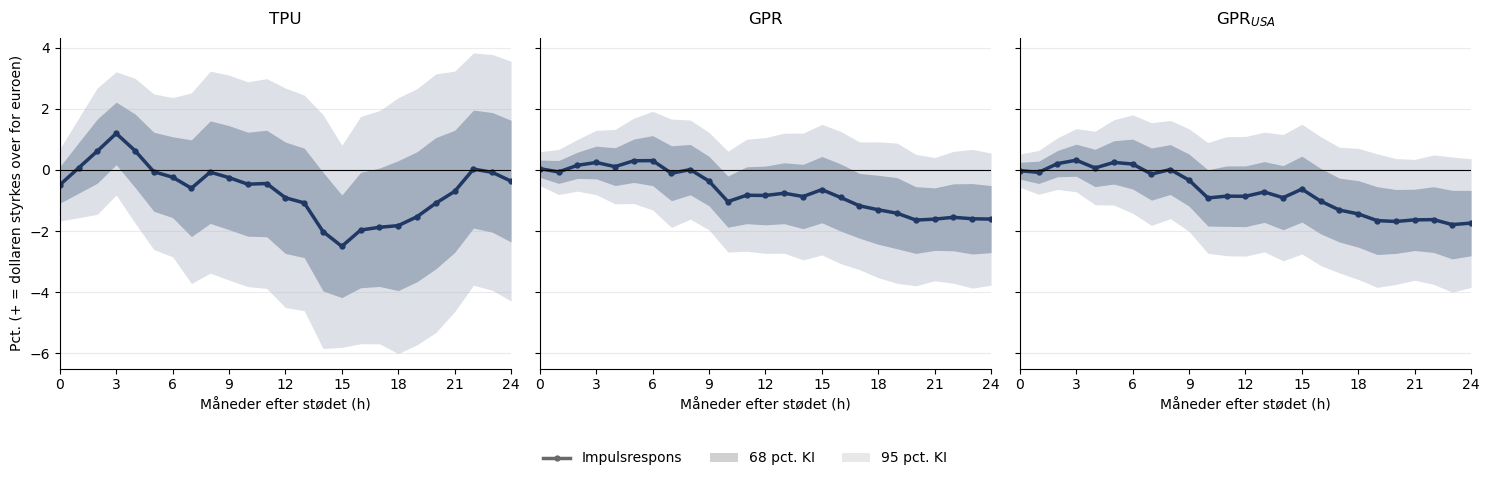

===== lnTPU_z | brud april 2025 =====


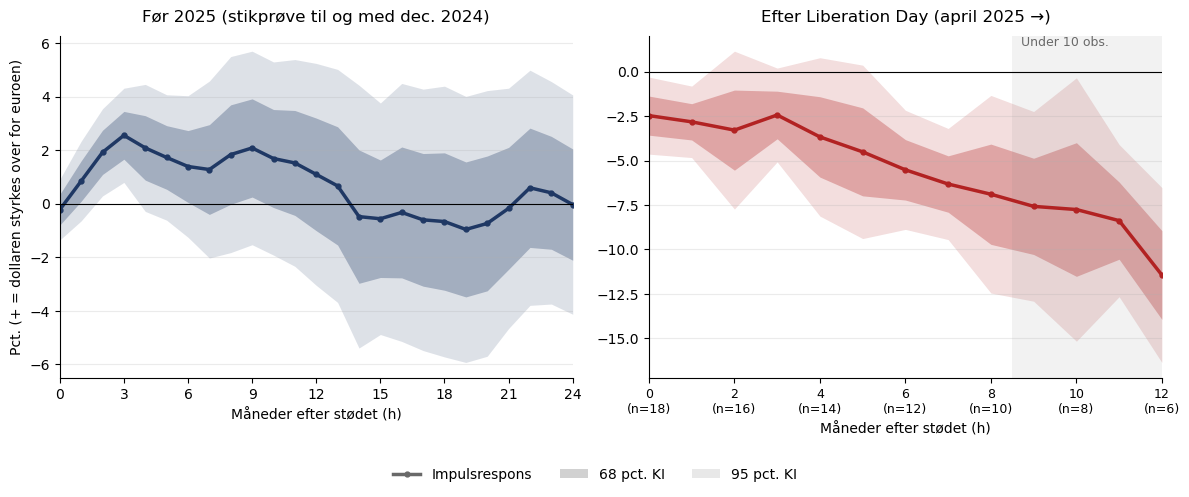

===== lnGPR_z | brud april 2025 =====


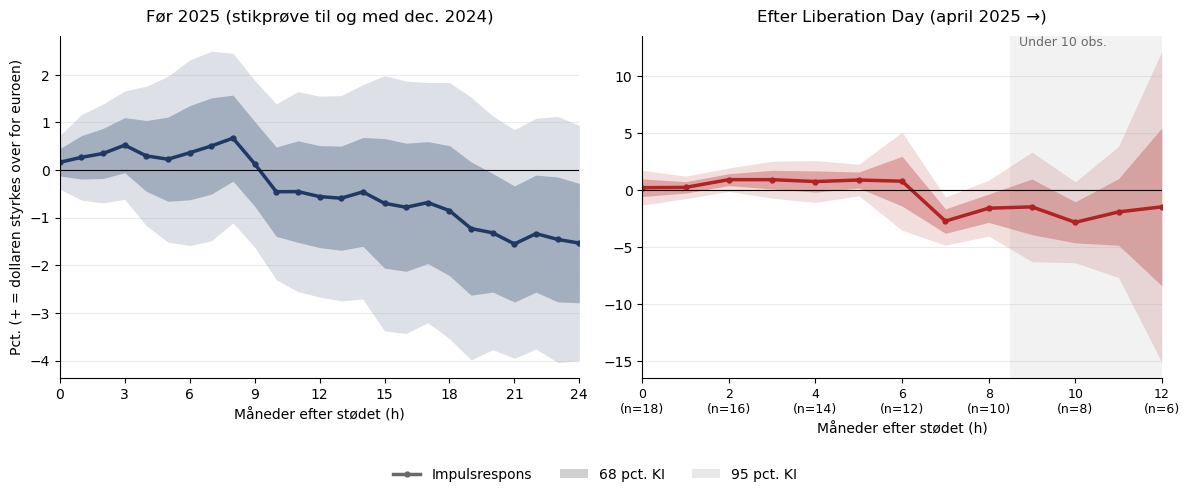

===== lnGPRC_USA_z | brud april 2025 =====


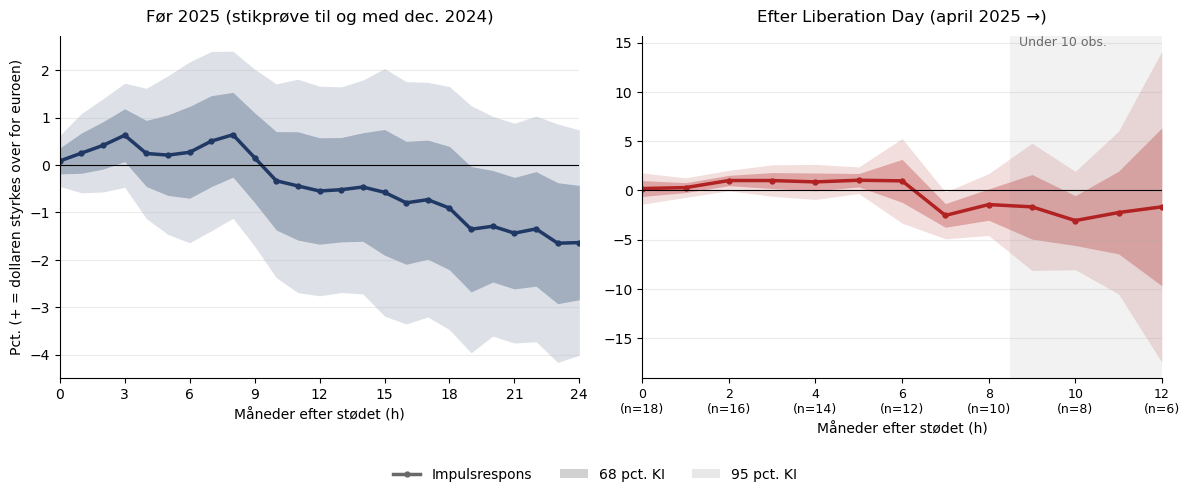

===== lnGPR_z | brud februar 2022 =====


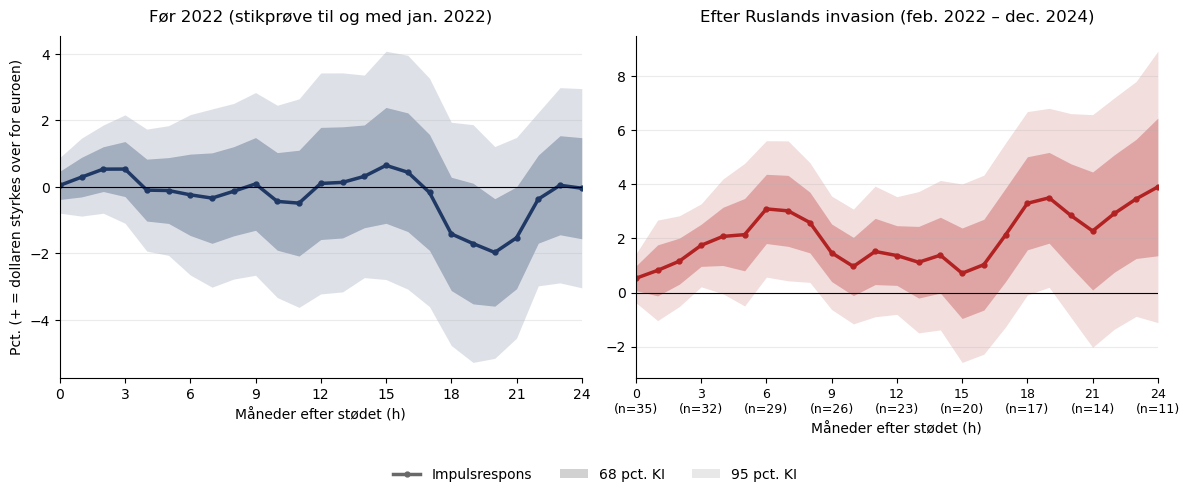

===== lnGPRC_USA_z | brud februar 2022 =====


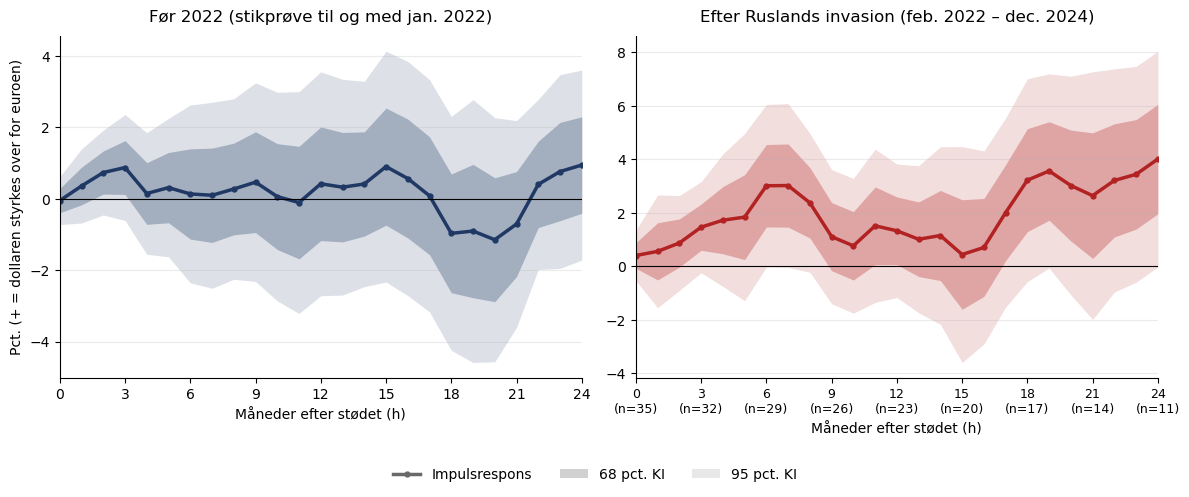

In [ ]:
# ---------- Hele perioden (tre paneler) ----------
fuld_usd = lp_figur_fuld("lp_fuld_hc3", y="lnUSD", ylabel=YL_USD, H=24, tick=3)

# ---------- Før/efter april 2025 ----------
figurresultater = {}
for s, fnavn, tnavn, kort in STOED:
    print(f"===== {s} | brud april 2025 =====")
    figurresultater[(s, "2025")] = lp_figur_foer_efter(s, f"lp_{kort}_foer_efter_hc3")

# ---------- Før/efter februar 2022 (GPR-indeksene) ----------
for s, fnavn, tnavn, kort in STOED[1:]:
    print(f"===== {s} | brud februar 2022 =====")
    figurresultater[(s, "2022")] = lp_figur_foer_efter(
        s, f"lp_{kort}_foer_efter_2022_hc3", brud="post_RU", pre_slut="2022-01-31",
        post_slut="2024-12-31", titel_pre="Før 2022 (stikprøve til og med jan. 2022)",
        titel_post="Efter Ruslands invasion (feb. 2022 – dec. 2024)", H_post=24)

In [ ]:
# ---------- Tabeller i notebooken ----------
if VIS_TABELLER:
    for (s, brud), pp in figurresultater.items():
        vis_foer_efter(pp, f"EUR/USD | {s} | brud {brud}")


===== EUR/USD | lnTPU_z | brud 2025 | VENSTRE PANEL: før bruddet =====


,h,coef,se,p,sig,n
0,0,-0.224,0.577,0.698,,117
1,1,0.845,0.759,0.266,,116
2,2,1.917,0.830,0.021,**,115
3,3,2.553,0.897,0.004,***,114
4,4,2.083,1.210,0.085,*,113
5,5,1.726,1.194,0.148,,112
6,6,1.389,1.348,0.303,,111
7,7,1.276,1.685,0.449,,110
8,8,1.834,1.867,0.326,,109
9,9,2.081,1.843,0.259,,108


===== EUR/USD | lnTPU_z | brud 2025 | HØJRE PANEL: efter bruddet + forskel =====


,h,coef_post,se_post,p_post,sig_post,coef_int,p_int,sig_int,n_post
0,0,-2.471,1.107,0.026,**,-2.152,0.036,**,18
1,1,-2.822,1.026,0.006,***,-3.149,0.003,***,17
2,2,-3.288,2.267,0.147,,-4.286,0.040,**,16
3,3,-2.437,1.348,0.071,*,-4.023,0.005,***,15
4,4,-3.671,2.274,0.107,,-4.747,0.034,**,14
5,5,-4.512,2.490,0.070,*,-4.915,0.047,**,13
6,6,-5.525,1.710,0.001,***,-5.653,0.002,***,12
7,7,-6.323,1.596,0.000,***,-6.006,0.001,***,11
8,8,-6.897,2.838,0.015,**,-7.175,0.015,**,10
9,9,-7.580,2.724,0.005,***,-7.788,0.008,***,9



===== EUR/USD | lnGPR_z | brud 2025 | VENSTRE PANEL: før bruddet =====


,h,coef,se,p,sig,n
0,0,0.162,0.288,0.573,,117
1,1,0.267,0.458,0.560,,116
2,2,0.347,0.529,0.512,,115
3,3,0.522,0.581,0.369,,114
4,4,0.296,0.748,0.693,,113
5,5,0.227,0.888,0.798,,112
6,6,0.362,0.993,0.715,,111
7,7,0.504,1.015,0.619,,110
8,8,0.670,0.909,0.461,,109
9,9,0.132,0.894,0.882,,108


... (10 outputs left out)


===== EUR/USD | lnGPRC_USA_z | brud 2022 | VENSTRE PANEL: før bruddet =====


,h,coef,se,p,sig,n
0,0,-0.051,0.343,0.883,,82
1,1,0.359,0.530,0.498,,81
2,2,0.736,0.606,0.225,,80
3,3,0.876,0.757,0.248,,79
4,4,0.149,0.869,0.864,,78
5,5,0.314,0.989,0.751,,77
6,6,0.137,1.270,0.914,,76
7,7,0.099,1.329,0.941,,75
8,8,0.275,1.290,0.831,,74
9,9,0.466,1.419,0.742,,73


===== EUR/USD | lnGPRC_USA_z | brud 2022 | HØJRE PANEL: efter bruddet + forskel =====


,h,coef_post,se_post,p_post,sig_post,coef_int,p_int,sig_int,n_post
0,0,0.405,0.481,0.400,,0.369,0.549,,35
1,1,0.562,1.076,0.602,,0.286,0.804,,34
2,2,0.874,0.905,0.334,,0.472,0.631,,33
3,3,1.465,0.869,0.092,*,0.913,0.433,,32
4,4,1.726,1.264,0.172,,1.782,0.261,,31
5,5,1.842,1.597,0.249,,1.949,0.301,,30
6,6,3.015,1.551,0.052,*,3.274,0.084,*,29
7,7,3.023,1.563,0.053,*,2.860,0.126,,28
8,8,2.377,1.325,0.073,*,1.779,0.305,,27
9,9,1.111,1.280,0.386,,0.713,0.687,,26


In [ ]:
# ---------- LaTeX-tabeller ----------
NOTE_LP = (r"Koefficienter fra ligning \eqref{eq:lp_final} for et stød på én standardafvigelse "
           r"i det log-transformerede usikkerhedsindeks. Responsen er målt i pct. (+ = dollaren "
           r"styrkes over for euroen). HC3-standardfejl i parentes. (1) Hele stikprøven. "
           r"(2) Stikprøve til og med december 2024. (3) Responsen efter april 2025, "
           r"$\beta_h+\phi_h$, fra ligning \eqref{eq:lp_dummy}. (4) Interaktionsleddet $\phi_h$, "
           r"dvs. forskellen mellem perioderne. $n_{\text{post}}$ angiver antallet af "
           r"observationer efter bruddet. Der vises kun horisonter med mindst 10 observationer "
           r"efter bruddet. $^{*}$, $^{**}$ og $^{***}$ angiver signifikans på "
           r"10, 5 og 1 pct.-niveau.")

TITLER_USD = {
    "lnTPU_z":      "Dollarens respons på et stød til handelspolitisk usikkerhed (TPU)",
    "lnGPR_z":      "Dollarens respons på et stød til geopolitisk risiko (GPR)",
    "lnGPRC_USA_z": r"Dollarens respons på et stød til geopolitisk risiko for USA ($\text{GPR}_{\text{USA}}$)",
}
for i, (s, fnavn, tnavn, kort) in enumerate(STOED):
    tex = lp_tabel(figurresultater[(s, "2025")], fuld_usd[s], TITLER_USD[s], f"tab:lp_{kort}",
                   HOR_POST, NOTE_LP if i == 0 else r"Se note til tabel \ref{tab:lp_tpu}.")
    if i == 0:
        print(tex)

Gemt: TABLES/lp_tpu.tex
\begin{table}[H]
\centering
\caption{Dollarens respons på et stød til handelspolitisk usikkerhed (TPU)}
\label{tab:lp_tpu}
\begin{threeparttable}
\begin{tabular}{l cccc c}
\toprule
 & (1) & (2) & (3) & (4) & \\
$h$ & Hele perioden & Før 2025 & Efter april 2025 & Forskel & $n_{\text{post}}$ \\
\midrule
0 & $-0.49$ & $-0.22$ & $-2.47^{**}$ & $-2.15^{**}$ & 18 \\
 & $(0.60)$ & $(0.58)$ & $(1.11)$ & $(1.02)$ & \\[2pt]
1 & $0.06$ & $0.84$ & $-2.82^{***}$ & $-3.15^{***}$ & 17 \\
 & $(0.83)$ & $(0.76)$ & $(1.03)$ & $(1.07)$ & \\[2pt]
2 & $0.62$ & $1.92^{**}$ & $-3.29$ & $-4.29^{**}$ & 16 \\
 & $(1.06)$ & $(0.83)$ & $(2.27)$ & $(2.09)$ & \\[2pt]
3 & $1.20$ & $2.55^{***}$ & $-2.44^{*}$ & $-4.02^{***}$ & 15 \\
 & $(1.03)$ & $(0.90)$ & $(1.35)$ & $(1.45)$ & \\[2pt]
4 & $0.63$ & $2.08^{*}$ & $-3.67$ & $-4.75^{**}$ & 14 \\
 & $(1.21)$ & $(1.21)$ & $(2.27)$ & $(2.23)$ & \\[2pt]
5 & $-0.06$ & $1.73$ & $-4.51^{*}$ & $-4.91^{**}$ & 13 \\
 & $(1.30)$ & $(1.19)$ & $(2.49)$ & $(2.4

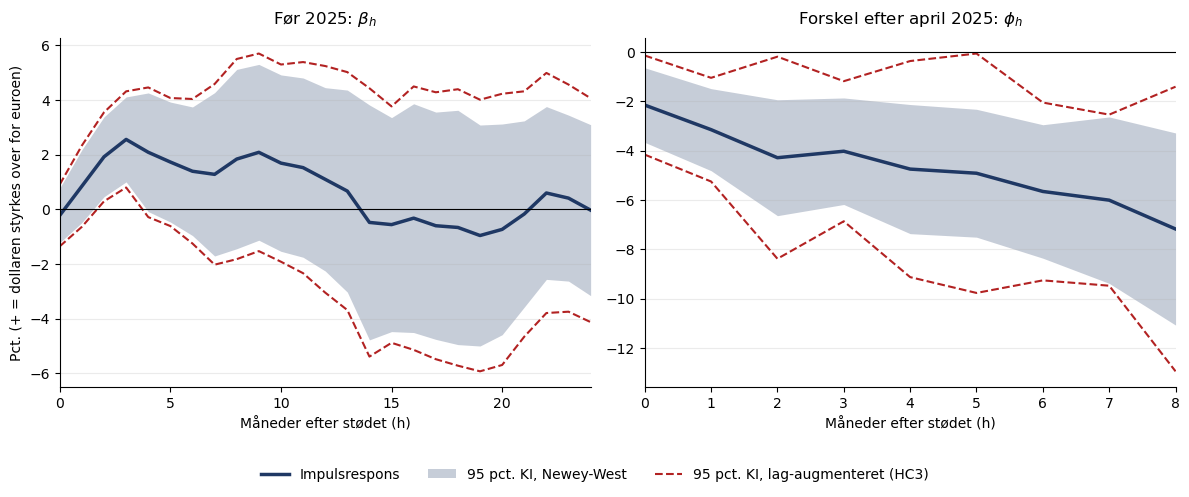

In [ ]:
# ---------- Newey-West vs. lag-augmenteret (HC3), jf. Jordà & Taylor (2025, figur 4) ----------
SPECS_SE = [("lnTPU_z", dict(H=24, slut="2024-12-31"),     "coef",     "se",     r"Før 2025: $\beta_h$"),
            ("lnTPU_z", dict(H=H_POST, dummy="post_LD"),   "coef_int", "se_int", r"Forskel efter april 2025: $\phi_h$")]

fig, akser = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (s, kw, kol, sekol, titel) in zip(akser, SPECS_SE):
    hc3 = lp(master, "lnUSD", s, se="hc3", **kw)
    nw  = lp(master, "lnUSD", s, se="nw",  **kw)
    ax.fill_between(nw["h"], nw[kol] - z95 * nw[sekol], nw[kol] + z95 * nw[sekol],
                    color=BLAA, alpha=0.25, lw=0)
    for fortegn in (-1, 1):
        ax.plot(hc3["h"], hc3[kol] + fortegn * z95 * hc3[sekol], ls="--", color=ROED, lw=1.5)
    ax.plot(hc3["h"], hc3[kol], color=BLAA, lw=2.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(titel, fontsize=12, pad=10); ax.set_xlabel("Måneder efter stødet (h)")
    ax.set_xlim(0, kw["H"]); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
akser[0].set_ylabel(YL_USD)

handles = [Line2D([0], [0], color=BLAA, lw=2.5, label="Impulsrespons"),
           Patch(facecolor=BLAA, alpha=0.25, label="95 pct. KI, Newey-West"),
           Line2D([0], [0], color=ROED, ls="--", lw=1.5, label="95 pct. KI, lag-augmenteret (HC3)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.06, 1, 1))
gem_fig("lp_tpu_nw_vs_hc3"); plt.show()

## 7. EUR/USD: robusthed
Hver række ændrer én ting i forhold til baseline. Ud over standardtjekkene indgår den effektive toldsats (lagget og samtidig), en covid-dummy og to alternative mål for dollaren.

In [ ]:
NOTE_ROB = (r"Responsen i pct. (+ = dollaren styrkes over for euroen) på et stød på én "
            r"standardafvigelse. Hver række ændrer én ting i forhold til baseline-specifikationen "
            r"i ligning \eqref{eq:lp_final}. Toldsatsen er ændringen i den effektive toldsats "
            r"(beregnet told i forhold til importværdien) og indgår med lags som de øvrige kontroller. "
            r"Stjerner angiver signifikans baseret på HC3-standardfejl, bortset fra rækken med "
            r"Newey-West-standardfejl. $^{*}$, $^{**}$ og $^{***}$ angiver signifikans på "
            r"10, 5 og 1 pct.-niveau.")

# GPR og GPR_USA: hele perioden er hovedresultatet
for s, fnavn, tnavn, kort in STOED[1:]:
    koef, n = robusthed("lnUSD", s, EPISODER_GPR_LP, ekstra_specs=EKSTRA_Y)
    print(f"\n===== Robusthed | {s} | hele perioden ====="); display(koef)
    robust_tex(koef, f"Robusthed: dollarens respons på et {tnavn}-stød", f"tab:rob_{kort}",
               NOTE_ROB if kort == "gpr" else r"Se note til tabel \ref{tab:rob_gpr}.")

# TPU (a): før 2025
koef, n = robusthed("lnUSD", "lnTPU_z", EPISODER_TPU_LP, slut="2024-12-31",
                    horisonter=(0, 1, 2, 3, 4, 6, 12, 24), ekstra_specs=EKSTRA_Y)
print("\n===== Robusthed | TPU | før 2025 ====="); display(koef)
robust_tex(koef, "Robusthed: dollarens respons på et TPU-stød før 2025", "tab:rob_tpu_foer",
           r"Som tabel \ref{tab:rob_gpr}, men alle specifikationer er estimeret på stikprøven til "
           r"og med december 2024. Episodeudeladelsen omfatter dermed kun handelskrigen 2018--2019.")

# TPU (b): forskellen før/efter april 2025 (phi_h)
koef, n = robusthed("lnUSD", "lnTPU_z", H=H_POST, dummy="post_LD", kol="coef_int", pkol="p_int",
                    horisonter=HOR_POST, ekstra_specs=EKSTRA_Y)
print("\n===== Robusthed | TPU | forskel før/efter april 2025 ====="); display(koef)
robust_tex(koef, "Robusthed: forskellen i dollarens respons på et TPU-stød før og efter april 2025",
           "tab:rob_tpu_brud",
           r"Koefficienten på interaktionsleddet $\phi_h$ i ligning \eqref{eq:lp_dummy}, dvs. "
           r"forskellen mellem responsen efter og før april 2025. Øvrige forhold som i note til "
           r"tabel \ref{tab:rob_gpr}.")


===== Robusthed | lnGPR_z | hele perioden =====


,0,3,6,12,18,24
Baseline,0.04 (0.882),0.24 (0.649),0.31 (0.711),-0.84 (0.387),-1.31 (0.251),-1.61 (0.145)
Newey-West-standardfejl,0.04 (0.865),0.24 (0.611),0.31 (0.640),-0.84 (0.253),-1.31 (0.011),-1.61 (0.007)
1 lag,0.10 (0.694),0.22 (0.658),0.26 (0.732),-0.90 (0.361),-1.64 (0.149),-2.08 (0.064)
3 lags,0.02 (0.939),0.24 (0.673),0.31 (0.700),-0.93 (0.308),-1.52 (0.166),-1.75 (0.109)
+ OIS-spænd (lagget),0.05 (0.863),0.24 (0.654),0.31 (0.706),-1.07 (0.266),-1.45 (0.190),-1.69 (0.134)
+ VIX (lagget),0.04 (0.884),0.25 (0.656),0.30 (0.723),-0.83 (0.398),-1.21 (0.288),-1.44 (0.155)
+ toldsats (lagget),0.04 (0.896),0.23 (0.669),0.28 (0.730),-1.05 (0.306),-1.36 (0.237),-1.52 (0.175)
+ covid-dummy,0.02 (0.941),0.13 (0.805),0.12 (0.889),-1.04 (0.295),-1.32 (0.258),-1.30 (0.197)
Niveauer i stedet for Δy,0.07 (0.792),0.33 (0.424),0.44 (0.469),0.13 (0.832),-0.34 (0.578),-1.05 (0.182)
Fast stikprøve,0.13 (0.651),0.52 (0.369),0.46 (0.629),-0.55 (0.585),-1.10 (0.341),-1.61 (0.145)


Gemt: TABLES/rob_gpr.tex

===== Robusthed | lnGPRC_USA_z | hele perioden =====


,0,3,6,12,18,24
Baseline,-0.02 (0.930),0.32 (0.546),0.19 (0.814),-0.86 (0.388),-1.44 (0.189),-1.74 (0.105)
Newey-West-standardfejl,-0.02 (0.921),0.32 (0.504),0.19 (0.765),-0.86 (0.269),-1.44 (0.003),-1.74 (0.008)
1 lag,0.06 (0.826),0.26 (0.587),0.15 (0.843),-1.00 (0.320),-1.83 (0.079),-2.23 (0.029)
3 lags,-0.01 (0.969),0.36 (0.526),0.31 (0.706),-0.76 (0.436),-1.42 (0.197),-1.66 (0.128)
+ OIS-spænd (lagget),-0.02 (0.950),0.33 (0.540),0.22 (0.790),-1.09 (0.271),-1.59 (0.133),-1.83 (0.093)
+ VIX (lagget),-0.03 (0.926),0.32 (0.555),0.18 (0.833),-0.86 (0.399),-1.36 (0.223),-1.55 (0.114)
+ toldsats (lagget),-0.03 (0.911),0.30 (0.570),0.17 (0.838),-1.07 (0.306),-1.46 (0.191),-1.67 (0.125)
+ covid-dummy,-0.05 (0.866),0.21 (0.699),-0.01 (0.992),-1.10 (0.281),-1.50 (0.182),-1.45 (0.150)
Niveauer i stedet for Δy,-0.01 (0.976),0.38 (0.355),0.32 (0.606),0.05 (0.933),-0.54 (0.400),-1.25 (0.136)
Fast stikprøve,0.05 (0.870),0.63 (0.263),0.34 (0.719),-0.56 (0.601),-1.22 (0.278),-1.74 (0.105)


Gemt: TABLES/rob_gpr_usa.tex

===== Robusthed | TPU | før 2025 =====


,0,1,2,3,4,6,12,24
Baseline,-0.22 (0.698),0.84 (0.266),1.92 (0.021),2.55 (0.004),2.08 (0.085),1.39 (0.303),1.09 (0.605),-0.03 (0.987)
Newey-West-standardfejl,-0.22 (0.661),0.84 (0.213),1.92 (0.010),2.55 (0.001),2.08 (0.060),1.39 (0.247),1.09 (0.522),-0.03 (0.983)
1 lag,-0.44 (0.427),0.62 (0.379),1.30 (0.113),1.97 (0.017),1.39 (0.190),0.85 (0.501),0.57 (0.767),0.08 (0.976)
3 lags,-0.26 (0.655),0.85 (0.256),1.94 (0.021),2.56 (0.008),2.10 (0.098),1.42 (0.335),1.06 (0.636),0.65 (0.759)
+ OIS-spænd (lagget),-0.26 (0.657),0.79 (0.318),1.74 (0.046),2.27 (0.020),1.77 (0.175),1.21 (0.404),0.82 (0.716),0.43 (0.829)
+ VIX (lagget),-0.22 (0.708),0.86 (0.269),1.93 (0.028),2.55 (0.007),2.04 (0.110),1.35 (0.372),1.11 (0.630),0.03 (0.989)
+ toldsats (lagget),-0.24 (0.676),0.82 (0.289),1.85 (0.024),2.39 (0.005),1.87 (0.102),1.25 (0.345),0.91 (0.670),0.06 (0.979)
+ covid-dummy,-0.25 (0.666),0.83 (0.283),1.87 (0.029),2.39 (0.010),1.76 (0.155),1.10 (0.427),0.82 (0.709),0.47 (0.818)
Niveauer i stedet for Δy,-0.28 (0.638),0.74 (0.313),1.63 (0.010),2.09 (0.005),1.39 (0.156),0.31 (0.736),-0.90 (0.384),-1.72 (0.142)
Fast stikprøve,-0.58 (0.379),0.49 (0.591),1.65 (0.094),2.40 (0.020),1.95 (0.161),1.55 (0.350),0.99 (0.679),-0.03 (0.987)


Gemt: TABLES/rob_tpu_foer.tex

===== Robusthed | TPU | forskel før/efter april 2025 =====


,0,1,2,3,4,5,6,7,8
Baseline,-2.15 (0.036),-3.15 (0.003),-4.29 (0.040),-4.02 (0.005),-4.75 (0.034),-4.91 (0.047),-5.65 (0.002),-6.01 (0.001),-7.18 (0.015)
Newey-West-standardfejl,-2.15 (0.005),-3.15 (0.000),-4.29 (0.000),-4.02 (0.000),-4.75 (0.000),-4.91 (0.000),-5.65 (0.000),-6.01 (0.000),-7.18 (0.000)
1 lag,-1.76 (0.072),-2.73 (0.003),-3.57 (0.042),-3.23 (0.014),-3.80 (0.046),-3.99 (0.049),-4.78 (0.000),-4.65 (0.000),-5.59 (0.003)
3 lags,-1.99 (0.069),-3.33 (0.007),-4.41 (0.044),-4.22 (0.011),-4.60 (0.050),-4.85 (0.063),-5.63 (0.010),-6.40 (0.013),-7.53 (0.031)
+ OIS-spænd (lagget),-2.17 (0.038),-3.45 (0.003),-4.77 (0.026),-4.64 (0.004),-5.46 (0.024),-5.58 (0.033),-6.05 (0.005),-6.30 (0.007),-7.69 (0.030)
+ VIX (lagget),-2.10 (0.043),-3.03 (0.003),-4.23 (0.041),-3.95 (0.006),-4.64 (0.035),-4.75 (0.057),-5.24 (0.011),-5.51 (0.008),-6.69 (0.036)
+ toldsats (lagget),-2.16 (0.115),-3.39 (0.003),-4.84 (0.066),-5.05 (0.001),-7.94 (0.001),-8.16 (0.005),-8.12 (0.004),-7.71 (0.012),-9.63 (0.009)
+ covid-dummy,-2.14 (0.038),-3.13 (0.003),-4.26 (0.042),-3.92 (0.007),-4.43 (0.055),-4.50 (0.086),-5.26 (0.009),-5.62 (0.004),-6.59 (0.045)
Niveauer i stedet for Δy,-1.65 (0.059),-2.26 (0.014),-2.98 (0.039),-2.21 (0.052),-2.25 (0.065),-1.68 (0.195),-0.73 (0.686),-0.08 (0.973),-0.80 (0.683)
Bredt dollarindeks,-1.13 (0.109),-1.75 (0.031),-2.43 (0.051),-2.47 (0.011),-2.59 (0.067),-2.27 (0.105),-2.71 (0.014),-2.78 (0.022),-3.67 (0.045)


Gemt: TABLES/rob_tpu_brud.tex


## 8. EUR/USD: bootstrap (punktvis og sup-t)

In [ ]:
# Standard: B=999, n_lags=2. Test evt. først med B=99.
bs = {
    "TPU (før 2025)":             lp_bootstrap(master, "lnTPU_z", slut="2024-12-31"),
    "GPR":                        lp_bootstrap(master, "lnGPR_z"),
    r"$\text{GPR}_{\text{USA}}$": lp_bootstrap(master, "lnGPRC_USA_z"),
}
HOR_BS = (0, 1, 2, 3, 4, 6, 12, 18, 24)

for navn, r in bs.items():
    print(f"\n===== Bootstrap | {navn} | sup-t kritisk værdi = {r.attrs['q_sup']:.2f} =====")
    display(r.loc[r["h"].isin(HOR_BS), ["h", "coef", "p", "p_boot", "lo95", "hi95", "beta_var"]].round(3))

linjer = []
for i, (navn, r) in enumerate(bs.items()):
    r = r.set_index("h")
    linjer.append(rf"\multicolumn{{5}}{{l}}{{\textit{{Panel {'ABC'[i]}: {navn}}}}} \\")
    for h in HOR_BS:
        if h in r.index:
            linjer.append(f"{h} & ${r.loc[h, 'coef']:.2f}$ & ${r.loc[h, 'p']:.3f}$ & "
                          f"${r.loc[h, 'p_boot']:.3f}$ & "
                          f"$[{r.loc[h, 'lo95']:.2f};\\ {r.loc[h, 'hi95']:.2f}]$ \\\\")
    linjer.append(r"\addlinespace")

tex = (r"""\begin{table}[H]
\centering
\caption{Bootstrap-baseret inferens}
\label{tab:bootstrap}
\begin{threeparttable}
\begin{tabular}{c cccc}
\toprule
$h$ & Koefficient & $p$ (HC3) & $p$ (bootstrap) & 95 pct. bootstrap-KI \\
\midrule
""" + "\n".join(linjer[:-1]) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} Responsen i pct. (+ = dollaren styrkes over for euroen) på et stød på
én standardafvigelse, estimeret med ligning \eqref{eq:lp_final}. Bootstrap-p-værdier og
percentile-t-konfidensintervaller er baseret på 999 wild bootstrap-replikationer fra den
tilsvarende VAR(2), jf. Montiel Olea og Plagborg-Møller (2021, afsnit 5). TPU er estimeret
på stikprøven til og med december 2024.
\end{tablenotes}
\end{threeparttable}
\end{table}""")
gem_tex(tex, "tab:bootstrap")


===== Bootstrap | TPU (før 2025) | sup-t kritisk værdi = 3.34 =====


,h,coef,p,p_boot,lo95,hi95,beta_var
0,0,-0.224,0.698,0.631,-1.127,0.802,-0.224
1,1,0.845,0.266,0.200,-0.507,2.287,0.792
2,2,1.917,0.021,0.028,0.529,3.796,0.919
3,3,2.553,0.004,0.006,0.957,4.556,1.261
4,4,2.083,0.085,0.090,-0.204,4.674,1.546
6,6,1.389,0.303,0.296,-0.830,4.406,1.820
12,12,1.094,0.605,0.605,-2.416,6.133,2.058
18,18,-0.666,0.796,0.806,-5.192,6.338,2.159
24,24,-0.034,0.987,0.991,-3.695,6.268,2.209



===== Bootstrap | GPR | sup-t kritisk værdi = 2.95 =====


,h,coef,p,p_boot,lo95,hi95,beta_var
0,0,0.042,0.882,0.872,-0.466,0.515,0.042
1,1,-0.067,0.859,0.822,-0.785,0.614,-0.091
2,2,0.152,0.726,0.706,-0.674,0.898,-0.058
3,3,0.245,0.649,0.605,-0.822,1.262,0.003
4,4,0.108,0.862,0.855,-1.005,1.269,0.065
6,6,0.305,0.711,0.699,-1.216,1.998,0.131
12,12,-0.837,0.387,0.395,-2.586,1.126,0.188
18,18,-1.306,0.251,0.282,-3.441,1.225,0.203
24,24,-1.611,0.145,0.164,-3.933,0.757,0.207



===== Bootstrap | $\text{GPR}_{\text{USA}}$ | sup-t kritisk værdi = 2.94 =====


,h,coef,p,p_boot,lo95,hi95,beta_var
0,0,-0.024,0.930,0.911,-0.512,0.388,-0.024
1,1,-0.079,0.829,0.794,-0.741,0.566,-0.130
2,2,0.206,0.633,0.608,-0.642,0.962,-0.065
3,3,0.319,0.546,0.505,-0.736,1.264,0.001
4,4,0.065,0.916,0.902,-1.041,1.215,0.066
6,6,0.193,0.814,0.795,-1.365,1.862,0.143
12,12,-0.864,0.388,0.401,-2.582,1.182,0.204
18,18,-1.441,0.189,0.211,-3.556,0.962,0.219
24,24,-1.742,0.105,0.132,-4.017,0.524,0.222


Gemt: TABLES/bootstrap.tex


## 9. Delspørgsmål 3: USD-hedge ratio
Samme model som for EUR/USD.

Hedge ratio: 2015-01-31 til 2026-09-30 (141 mdr.) | mdr. fra og med april 2025: 18


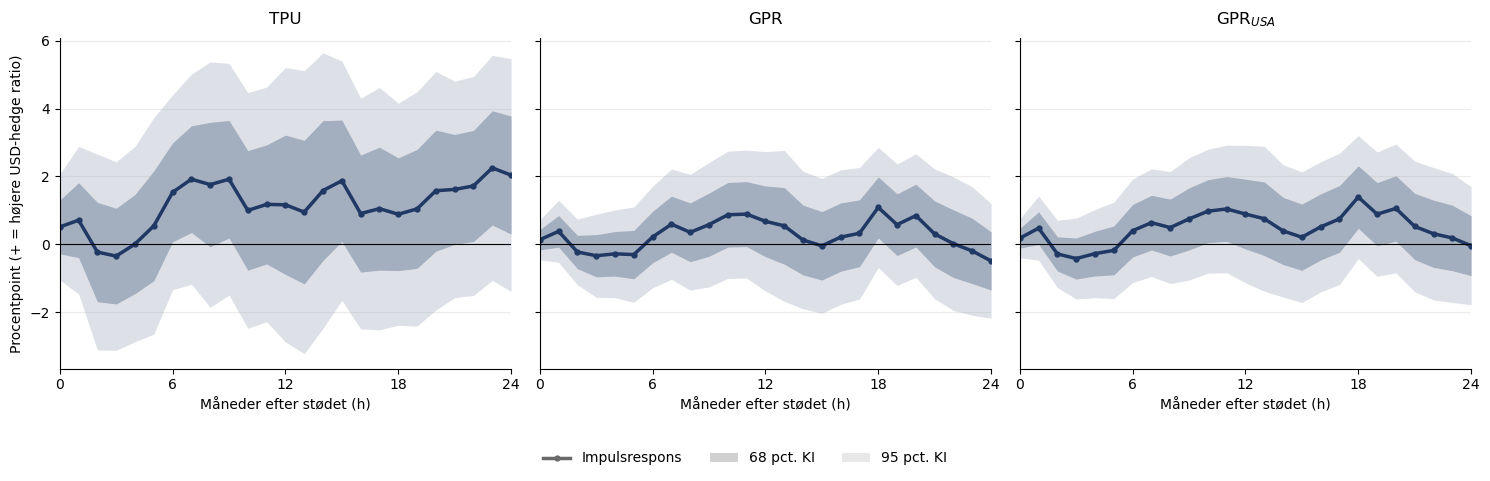

===== Hedge ratio | lnTPU_z | brud april 2025 =====


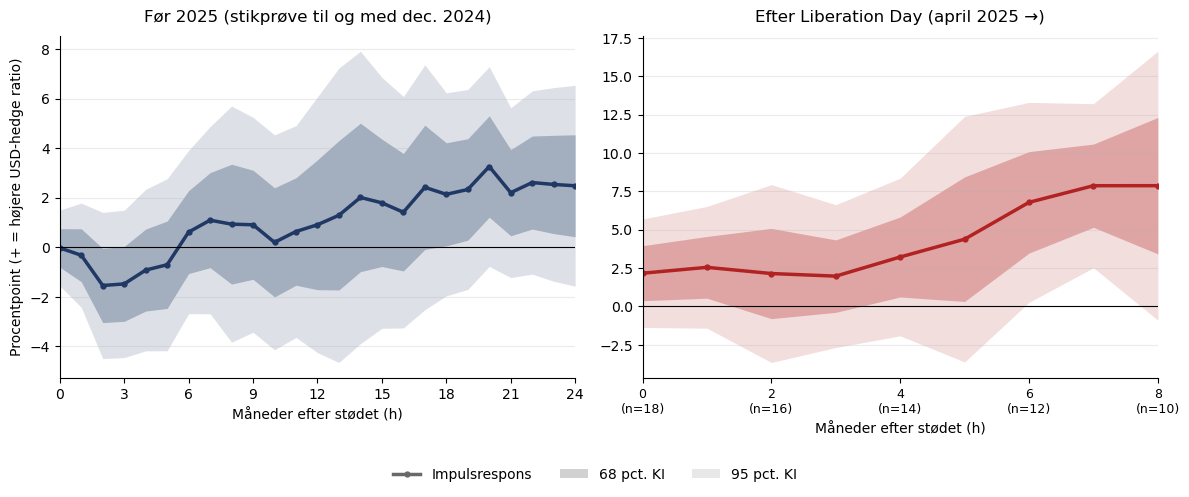

===== Hedge ratio | lnGPR_z | brud april 2025 =====


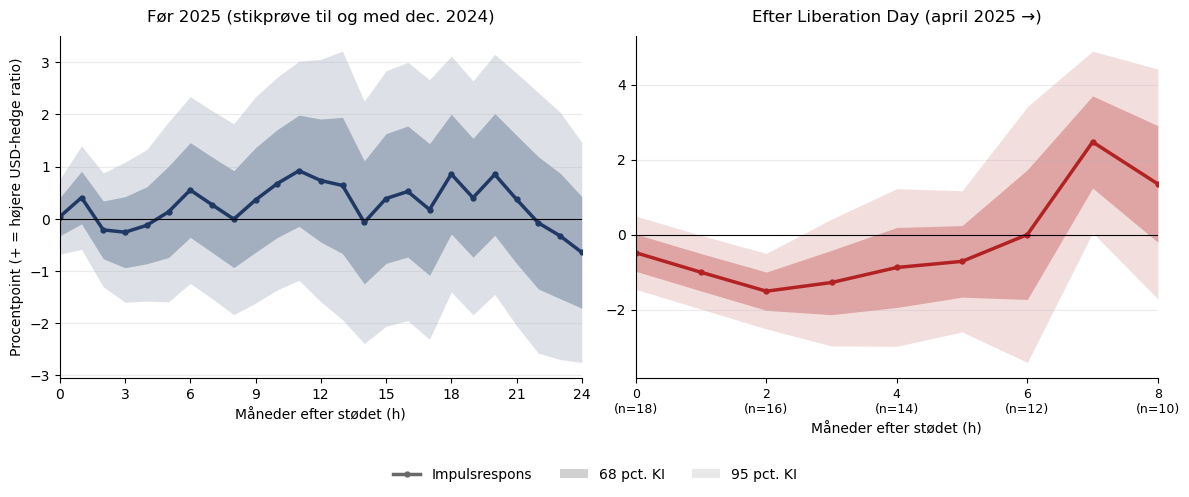

===== Hedge ratio | lnGPRC_USA_z | brud april 2025 =====


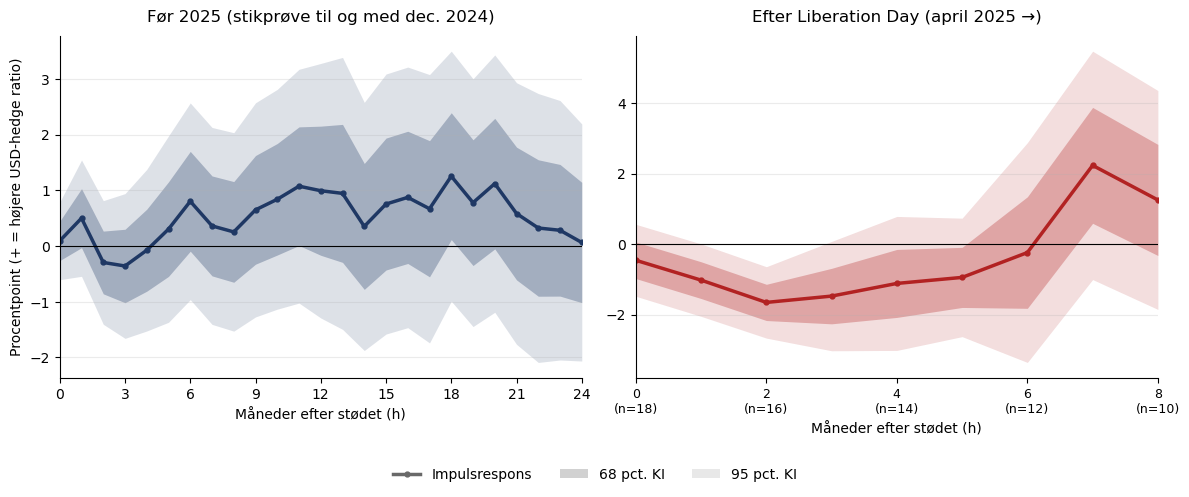

In [ ]:
N_LAGS_HR = 2      # baseline (se lag-valg i afsnit 5)
H_HR = 24

dh = master.dropna(subset=["hr"])
print(f"Hedge ratio: {dh['month'].min().date()} til {dh['month'].max().date()} "
      f"({len(dh)} mdr.) | mdr. fra og med april 2025: {int(dh['post_LD'].sum())}")

# ---------- Hele perioden ----------
fuld_hr = lp_figur_fuld("lp_hr_fuld", y="hr", ylabel=YL_HR, H=H_HR, tick=6, n_lags=N_LAGS_HR)

# ---------- Før 2025 / efter Liberation Day ----------
hr_res = {}
for s, fnavn, tnavn, kort in STOED:
    print(f"===== Hedge ratio | {s} | brud april 2025 =====")
    hr_res[(s, "2025")] = lp_figur_foer_efter(
        s, f"lp_hr_{kort}_foer_efter", y="hr", ylabel=YL_HR,
        H_pre=H_HR, H_post=H_POST_HR, n_lags=N_LAGS_HR)

In [ ]:
# ---------- Tabeller i notebooken og LaTeX ----------
if VIS_TABELLER:
    for (s, brud), pp in hr_res.items():
        vis_foer_efter(pp, f"Hedge ratio | {s} | brud {brud}")

NOTE_HR = (r"Koefficienter fra ligning \eqref{eq:lp_final} med USD-hedge ratioen som "
           r"afhængig variabel, målt i procentpoint (+ = højere afdækningsgrad). Øvrige "
           r"forhold som i note til tabel \ref{tab:lp_tpu}.")
for i, (s, fnavn, tnavn, kort) in enumerate(STOED):
    lp_tabel(hr_res[(s, "2025")], fuld_hr[s], f"USD-hedge ratioens respons på et {tnavn}-stød",
             f"tab:lp_hr_{kort}", HOR_POST_HR,
             NOTE_HR if i == 0 else r"Se note til tabel \ref{tab:lp_hr_tpu}.")


===== Hedge ratio | lnTPU_z | brud 2025 | VENSTRE PANEL: før bruddet =====


,h,coef,se,p,sig,n
0,0,-0.026,0.780,0.973,,117
1,1,-0.320,1.073,0.766,,116
2,2,-1.541,1.505,0.306,,115
3,3,-1.477,1.517,0.330,,114
4,4,-0.919,1.663,0.580,,113
5,5,-0.703,1.770,0.691,,112
6,6,0.613,1.680,0.715,,111
7,7,1.094,1.927,0.570,,110
8,8,0.933,2.430,0.701,,109
9,9,0.909,2.212,0.681,,108


===== Hedge ratio | lnTPU_z | brud 2025 | HØJRE PANEL: efter bruddet + forskel =====


,h,coef_post,se_post,p_post,sig_post,coef_int,p_int,sig_int,n_post
0,0,2.162,1.803,0.231,,1.822,0.252,,18
1,1,2.545,2.024,0.208,,2.026,0.284,,17
2,2,2.142,2.957,0.469,,2.621,0.328,,16
3,3,1.972,2.374,0.406,,2.585,0.253,,15
4,4,3.219,2.622,0.219,,3.552,0.158,,14
5,5,4.379,4.082,0.283,,4.211,0.290,,13
6,6,6.781,3.324,0.041,**,5.462,0.095,*,12
7,7,7.866,2.728,0.004,***,5.996,0.027,**,11
8,8,7.867,4.472,0.079,*,6.175,0.165,,10



===== Hedge ratio | lnGPR_z | brud 2025 | VENSTRE PANEL: før bruddet =====


,h,coef,se,p,sig,n
0,0,0.040,0.366,0.912,,117
1,1,0.408,0.507,0.421,,116
2,2,-0.211,0.557,0.704,,115
3,3,-0.256,0.685,0.709,,114
4,4,-0.123,0.741,0.868,,113
5,5,0.134,0.879,0.879,,112
6,6,0.553,0.913,0.545,,111
7,7,0.272,0.919,0.768,,110
8,8,-0.005,0.933,0.996,,109
9,9,0.362,1.009,0.720,,108


... (3 outputs left out)

,h,coef,se,p,sig,n
0,0,0.093,0.356,0.793,,117
1,1,0.500,0.533,0.348,,116
2,2,-0.295,0.566,0.602,,115
3,3,-0.358,0.663,0.589,,114
4,4,-0.075,0.740,0.920,,113
5,5,0.304,0.853,0.722,,112
6,6,0.803,0.901,0.373,,111
7,7,0.361,0.902,0.689,,110
8,8,0.253,0.909,0.780,,109
9,9,0.649,0.980,0.508,,108


===== Hedge ratio | lnGPRC_USA_z | brud 2025 | HØJRE PANEL: efter bruddet + forskel =====


,h,coef_post,se_post,p_post,sig_post,coef_int,p_int,sig_int,n_post
0,0,-0.459,0.522,0.378,,-0.776,0.179,,18
1,1,-1.024,0.525,0.051,*,-1.892,0.008,***,17
2,2,-1.656,0.517,0.001,***,-1.798,0.017,**,16
3,3,-1.476,0.793,0.063,*,-1.523,0.121,,15
4,4,-1.117,0.971,0.250,,-1.376,0.226,,14
5,5,-0.945,0.859,0.271,,-1.358,0.217,,13
6,6,-0.240,1.593,0.880,,-1.241,0.502,,12
7,7,2.238,1.655,0.176,,1.431,0.453,,11
8,8,1.255,1.587,0.429,,0.448,0.802,,10


Gemt: TABLES/lp_hr_tpu.tex
Gemt: TABLES/lp_hr_gpr.tex
Gemt: TABLES/lp_hr_gpr_usa.tex


In [ ]:
# ---------- Robusthed (standardtjek + hedge ratio-specifikke tjek) ----------
HR_EKSTRA = {
    "Værdieffekt (samtidigt aktieafkast)": {"samtidige": ("spxt_ret",)},
    "+ dollarafkast (lagget)":             {"extra_controls": ("dlnUSD",)},
}
for s, ep in [("lnTPU_z", EPISODER_TPU_LP), ("lnGPR_z", EPISODER_GPR_LP),
              ("lnGPRC_USA_z", EPISODER_GPR_LP)]:
    koef, n = robusthed("hr", s, ep, H=H_HR, n_lags=N_LAGS_HR, ekstra_specs=HR_EKSTRA)
    print(f"\n===== Hedge ratio robusthed | {s} ====="); display(koef); display(n)


===== Hedge ratio robusthed | lnTPU_z =====


,0,3,6,12,18,24
Baseline,0.51 (0.522),-0.35 (0.806),1.53 (0.296),1.16 (0.573),0.89 (0.596),2.04 (0.244)
Newey-West-standardfejl,0.51 (0.470),-0.35 (0.783),1.53 (0.205),1.16 (0.388),0.89 (0.540),2.04 (0.114)
1 lag,0.38 (0.592),-0.32 (0.811),1.05 (0.491),1.01 (0.642),1.22 (0.487),1.81 (0.304)
3 lags,0.56 (0.487),-0.39 (0.784),1.66 (0.277),1.06 (0.603),1.00 (0.546),1.89 (0.310)
+ OIS-spænd (lagget),0.60 (0.452),-0.18 (0.900),1.51 (0.311),0.96 (0.641),0.42 (0.806),1.93 (0.290)
+ VIX (lagget),0.51 (0.528),-0.40 (0.791),1.65 (0.258),1.05 (0.634),0.89 (0.607),2.00 (0.272)
+ toldsats (lagget),0.48 (0.550),-0.43 (0.765),1.43 (0.332),0.70 (0.733),0.79 (0.632),1.64 (0.347)
+ covid-dummy,0.50 (0.539),-0.19 (0.893),1.66 (0.264),0.91 (0.659),0.46 (0.784),1.73 (0.335)
Niveauer i stedet for Δy,0.26 (0.741),-1.03 (0.380),0.61 (0.572),-0.69 (0.582),-0.68 (0.508),0.52 (0.707)
Fast stikprøve,0.23 (0.778),-1.48 (0.330),0.57 (0.732),1.19 (0.657),1.96 (0.320),2.04 (0.244)


,0,3,6,12,18,24
Baseline,138,135,132,126,120,114
Newey-West-standardfejl,138,135,132,126,120,114
1 lag,139,136,133,127,121,115
3 lags,137,134,131,125,119,113
+ OIS-spænd (lagget),138,135,132,126,120,114
+ VIX (lagget),138,135,132,126,120,114
+ toldsats (lagget),138,135,132,126,120,114
+ covid-dummy,138,135,132,126,120,114
Niveauer i stedet for Δy,138,135,132,126,120,114
Fast stikprøve,114,114,114,114,114,114



===== Hedge ratio robusthed | lnGPR_z =====


,0,3,6,12,18,24
Baseline,0.13 (0.658),-0.34 (0.588),0.21 (0.779),0.68 (0.519),1.09 (0.230),-0.49 (0.568)
Newey-West-standardfejl,0.13 (0.616),-0.34 (0.502),0.21 (0.715),0.68 (0.435),1.09 (0.033),-0.49 (0.516)
1 lag,0.02 (0.942),-0.22 (0.723),0.26 (0.718),0.73 (0.481),1.39 (0.109),-0.14 (0.866)
3 lags,0.14 (0.637),-0.35 (0.568),0.17 (0.809),0.58 (0.564),1.07 (0.279),-0.47 (0.604)
+ OIS-spænd (lagget),0.10 (0.726),-0.36 (0.581),0.18 (0.812),0.65 (0.541),1.01 (0.285),-0.52 (0.551)
+ VIX (lagget),0.13 (0.676),-0.35 (0.586),0.23 (0.766),0.66 (0.533),1.07 (0.259),-0.59 (0.484)
+ toldsats (lagget),0.15 (0.629),-0.35 (0.579),0.24 (0.761),0.84 (0.435),0.82 (0.365),-0.83 (0.325)
+ covid-dummy,0.13 (0.678),-0.27 (0.671),0.26 (0.739),0.52 (0.622),0.90 (0.322),-0.67 (0.431)
Niveauer i stedet for Δy,0.07 (0.808),-0.56 (0.315),-0.10 (0.877),-0.13 (0.859),0.47 (0.492),-0.65 (0.333)
Fast stikprøve,0.05 (0.902),-0.26 (0.709),0.46 (0.599),0.60 (0.595),0.99 (0.294),-0.49 (0.568)


,0,3,6,12,18,24
Baseline,138,135,132,126,120,114
Newey-West-standardfejl,138,135,132,126,120,114
1 lag,139,136,133,127,121,115
3 lags,137,134,131,125,119,113
+ OIS-spænd (lagget),138,135,132,126,120,114
+ VIX (lagget),138,135,132,126,120,114
+ toldsats (lagget),138,135,132,126,120,114
+ covid-dummy,138,135,132,126,120,114
Niveauer i stedet for Δy,138,135,132,126,120,114
Fast stikprøve,114,114,114,114,114,114



===== Hedge ratio robusthed | lnGPRC_USA_z =====


,0,3,6,12,18,24
Baseline,0.18 (0.540),-0.42 (0.489),0.40 (0.607),0.89 (0.389),1.39 (0.133),-0.04 (0.961)
Newey-West-standardfejl,0.18 (0.493),-0.42 (0.413),0.40 (0.514),0.89 (0.313),1.39 (0.011),-0.04 (0.953)
1 lag,0.04 (0.891),-0.27 (0.643),0.45 (0.533),0.98 (0.314),1.74 (0.042),0.34 (0.700)
3 lags,0.15 (0.617),-0.54 (0.379),0.26 (0.726),0.65 (0.512),1.30 (0.194),-0.10 (0.920)
+ OIS-spænd (lagget),0.14 (0.633),-0.46 (0.469),0.37 (0.642),0.90 (0.389),1.35 (0.157),-0.05 (0.952)
+ VIX (lagget),0.18 (0.558),-0.44 (0.483),0.43 (0.590),0.87 (0.404),1.40 (0.148),-0.15 (0.867)
+ toldsats (lagget),0.19 (0.521),-0.43 (0.488),0.43 (0.593),1.09 (0.297),1.26 (0.178),-0.26 (0.772)
+ covid-dummy,0.18 (0.552),-0.35 (0.570),0.46 (0.560),0.75 (0.469),1.23 (0.185),-0.22 (0.800)
Niveauer i stedet for Δy,0.09 (0.747),-0.71 (0.177),-0.02 (0.978),-0.21 (0.773),0.44 (0.497),-0.51 (0.457)
Fast stikprøve,0.11 (0.750),-0.36 (0.589),0.73 (0.402),0.85 (0.443),1.32 (0.171),-0.04 (0.961)


,0,3,6,12,18,24
Baseline,138,135,132,126,120,114
Newey-West-standardfejl,138,135,132,126,120,114
1 lag,139,136,133,127,121,115
3 lags,137,134,131,125,119,113
+ OIS-spænd (lagget),138,135,132,126,120,114
+ VIX (lagget),138,135,132,126,120,114
+ toldsats (lagget),138,135,132,126,120,114
+ covid-dummy,138,135,132,126,120,114
Niveauer i stedet for Δy,138,135,132,126,120,114
Fast stikprøve,114,114,114,114,114,114


In [ ]:
# ---------- Aktiv afdækning eller mekanisk værdiregulering? ----------
# ln(hr) = ln(afdækket) - ln(eksponering), så responsen i hr kan opdeles.
for s, *_ in STOED:
    specs = {navn: lp(master, var, s, H=H_HR, n_lags=N_LAGS_HR)
             for navn, var in [("Afdækket beløb (log-pct.)", "ln_afd"),
                               ("Eksponering (log-pct.)",   "ln_eksp")]}
    koef, _ = sammenlign(specs, horisonter=tuple(h for h in (0, 3, 6, 12, 18, 24) if h <= H_HR))
    print(f"\n===== Dekomposition | {s} | hele perioden ====="); display(koef)

# Efter april 2025 (TPU)
specs_dk = {navn: lp(master, var, "lnTPU_z", H=H_POST_HR, n_lags=N_LAGS_HR, dummy="post_LD")
            for navn, var in [("Hedge ratio (pp)",          "hr"),
                              ("Afdækket beløb (log-pct.)", "ln_afd"),
                              ("Eksponering (log-pct.)",    "ln_eksp")]}
for kol, pkol, titel in [("coef_post", "p_post", "Efter april 2025"),
                         ("coef_int",  "p_int",  "Forskel (efter − før)")]:
    koef, _ = sammenlign(specs_dk, horisonter=HOR_POST_HR, kol=kol, pkol=pkol)
    print(f"\n===== Dekomposition | TPU | {titel} ====="); display(koef)


===== Dekomposition | lnTPU_z | hele perioden =====


,0,3,6,12,18,24
Afdækket beløb (log-pct.),0.07 (0.946),-0.02 (0.990),2.95 (0.109),2.08 (0.353),2.56 (0.232),2.69 (0.443)
Eksponering (log-pct.),-0.65 (0.538),0.47 (0.719),0.65 (0.640),0.56 (0.764),1.39 (0.403),-0.27 (0.908)



===== Dekomposition | lnGPR_z | hele perioden =====


,0,3,6,12,18,24
Afdækket beløb (log-pct.),-0.49 (0.259),-0.75 (0.270),-0.12 (0.864),-0.03 (0.975),0.69 (0.572),-0.62 (0.695)
Eksponering (log-pct.),-0.65 (0.091),-0.14 (0.885),-0.39 (0.681),-1.08 (0.407),-1.16 (0.361),-0.39 (0.748)



===== Dekomposition | lnGPRC_USA_z | hele perioden =====


,0,3,6,12,18,24
Afdækket beløb (log-pct.),-0.38 (0.401),-0.67 (0.323),0.13 (0.860),0.22 (0.834),0.94 (0.457),0.29 (0.849)
Eksponering (log-pct.),-0.60 (0.140),0.07 (0.947),-0.41 (0.671),-1.12 (0.375),-1.36 (0.263),-0.17 (0.879)



===== Dekomposition | TPU | Efter april 2025 =====


,0,1,2,3,4,5,6,7,8
Hedge ratio (pp),2.16 (0.231),2.55 (0.208),2.14 (0.469),1.97 (0.406),3.22 (0.219),4.38 (0.283),6.78 (0.041),7.87 (0.004),7.87 (0.079)
Afdækket beløb (log-pct.),1.03 (0.458),2.86 (0.128),2.80 (0.191),3.35 (0.140),4.21 (0.097),5.89 (0.195),10.92 (0.000),10.69 (0.000),10.59 (0.000)
Eksponering (log-pct.),-2.27 (0.362),-1.18 (0.589),-0.57 (0.856),-0.06 (0.982),-1.60 (0.607),-1.88 (0.502),0.28 (0.934),-1.04 (0.787),-1.77 (0.787)



===== Dekomposition | TPU | Forskel (efter − før) =====


,0,1,2,3,4,5,6,7,8
Hedge ratio (pp),1.82 (0.252),2.03 (0.284),2.62 (0.328),2.58 (0.253),3.55 (0.158),4.21 (0.290),5.46 (0.095),6.00 (0.027),6.17 (0.165)
Afdækket beløb (log-pct.),1.06 (0.314),2.00 (0.182),2.85 (0.083),3.75 (0.081),4.68 (0.067),5.77 (0.206),8.49 (0.004),8.60 (0.000),8.36 (0.001)
Eksponering (log-pct.),-1.78 (0.420),-1.23 (0.565),-1.16 (0.703),-0.58 (0.824),-1.64 (0.587),-1.88 (0.523),-0.25 (0.943),-0.59 (0.881),-1.85 (0.774)


In [ ]:
# ---------- LaTeX: dekomposition efter april 2025 (TPU) ----------
RAEKKER = [("Hedge ratio (pp)",          "Hedge ratio (pp)"),
           ("Afdækket beløb (log-pct.)", "Afdækket beløb (pct.)"),
           ("Eksponering (log-pct.)",    "Eksponering (pct.)")]
PANELER = [(r"Panel A: Efter april 2025 ($\beta_h+\phi_h$)", "coef_post", "se_post", "p_post"),
           (r"Panel B: Forskel ($\phi_h$)",                   "coef_int",  "se_int",  "p_int")]

def tal(x):
    return f"{x:.2f}"          # decimalkomma: f"{x:.2f}".replace(".", "{,}")

ncol = len(HOR_POST_HR) + 1
linjer = [r"\begin{table}[H]", r"\centering",
          r"\caption{Dekomposition af USD-hedge ratioens respons på et TPU-stød}",
          r"\label{tab:dekomp}", r"\begin{threeparttable}",
          r"\begin{tabular}{l" + "c" * len(HOR_POST_HR) + "}", r"\toprule",
          r"$h$ & " + " & ".join(str(h) for h in HOR_POST_HR) + r" \\", r"\midrule"]
for i, (ptitel, k, se_k, p_k) in enumerate(PANELER):
    if i > 0:
        linjer.append(r"\addlinespace")
    linjer.append(rf"\multicolumn{{{ncol}}}{{l}}{{\textit{{{ptitel}}}}} \\")
    for noegle, etiket in RAEKKER:
        r = specs_dk[noegle].set_index("h").reindex(HOR_POST_HR)
        linjer.append(etiket + " & " + " & ".join(
            f"${tal(r.loc[h, k])}{_stj(r.loc[h, p_k])}$" for h in HOR_POST_HR) + r" \\")
        linjer.append(" & " + " & ".join(f"({tal(r.loc[h, se_k])})" for h in HOR_POST_HR) + r" \\")

n_post = specs_dk["Hedge ratio (pp)"].set_index("h").reindex(HOR_POST_HR)["n_post"]
linjer += [r"\midrule",
           r"$n_{\text{post}}$ & " + " & ".join(str(int(n)) for n in n_post) + r" \\",
           r"\bottomrule", r"\end{tabular}",
           r"\begin{tablenotes}\footnotesize",
           r"\item \textit{Note:} Koefficienter fra ligning \eqref{eq:lp_dummy} med henholdsvis "
           r"USD-hedge ratioen (procentpoint), log til det afdækkede beløb og log til USD-eksponeringen "
           r"($\times 100$) som afhængig variabel. Da $\ln(\text{hedge ratio}) = \ln(\text{afdækket}) - "
           r"\ln(\text{eksponering})$, svarer forskellen mellem anden og tredje række tilnærmelsesvis til "
           r"den relative ændring i hedge ratioen. HC3-standardfejl i parentes. "
           r"$^{*}$, $^{**}$ og $^{***}$ angiver signifikans på 10, 5 og 1 pct.-niveau.",
           r"\end{tablenotes}", r"\end{threeparttable}", r"\end{table}"]
gem_tex("\n".join(linjer), "tab:dekomp", fil="dekomp_hr_tpu.tex")

Gemt: TABLES/dekomp_hr_tpu.tex


## 10. Bootstrap af bruddet efter april 2025 (EUR/USD og hedge ratio)

In [ ]:
BRUD_Y = [("lnUSD",  "EUR/USD (pct.)",                 H_POST),
          ("hr",     "USD-hedge ratio (procentpoint)", H_POST_HR),
          ("ln_afd", "Afdækket beløb (pct.)",          H_POST_HR)]

brud_bs, linjer = {}, []
for i, (yv, navn, H_) in enumerate(BRUD_Y):
    r = lp_bootstrap_brud(master, "lnTPU_z", y=yv, H=H_)
    brud_bs[yv] = r
    print(f"\n===== {navn} | h = 0–{H_} | sup-t: kritisk værdi = {r.attrs['q_sup']:.2f}, "
          f"p = {r.attrs['p_sup']:.3f} | gennemsnitlig forskel = {r.attrs['phibar']:.2f}, "
          f"p = {r.attrs['p_phibar']:.3f} =====")
    display(r[["h", "coef_int", "se_int", "p_int", "p_boot", "q95_boot", "n_post"]].round(3))

    linjer.append(rf"\multicolumn{{5}}{{l}}{{\textit{{Panel {'ABC'[i]}: {navn}}}}} \\")
    for _, rk in r.iterrows():
        linjer.append(f"{int(rk['h'])} & ${rk['coef_int']:.2f}$ & ${rk['p_int']:.3f}$ & "
                      f"${rk['p_boot']:.3f}$ & {int(rk['n_post'])} \\\\")
    linjer.append(rf"\multicolumn{{5}}{{l}}{{Fælles test (sup-t), $h=0,\dots,{H_}$: "
                  rf"$p = {r.attrs['p_sup']:.3f}$; gennemsnitlig forskel: "
                  rf"$p = {r.attrs['p_phibar']:.3f}$}} \\")
    linjer.append(r"\addlinespace")

tex = (r"""\begin{table}[H]
\centering
\caption{Bootstrap-baseret inferens for bruddet efter april 2025}
\label{tab:bootstrap_brud}
\begin{threeparttable}
\begin{tabular}{c cccc}
\toprule
$h$ & $\hat\phi_h$ & $p$ (HC3) & $p$ (bootstrap) & $n_{\text{post}}$ \\
\midrule
""" + "\n".join(linjer[:-1]) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} $\hat\phi_h$ er forskellen i responsen på et TPU-stød efter og før
april 2025 fra ligning \eqref{eq:lp_dummy}. Bootstrap-p-værdierne er baseret på 999
wild bootstrap-replikationer fra en VAR(2) uden brud, så den sande forskel er nul.
Den fælles test (sup-t) tester, at $\phi_h=0$ for alle viste horisonter, jf. Montiel Olea
og Plagborg-Møller (2019) og Jordà og Taylor (2025, afsnit 7.2). Testen af den
gennemsnitlige forskel tester, at gennemsnittet af $\phi_h$ over de viste horisonter er nul.
Der vises kun horisonter med mindst 10 observationer efter bruddet.
\end{tablenotes}
\end{threeparttable}
\end{table}""")
gem_tex(tex, "tab:bootstrap_brud")


===== EUR/USD (pct.) | h = 0–8 | sup-t: kritisk værdi = 4.76, p = 0.138 | gennemsnitlig forskel = -4.68, p = 0.255 =====


,h,coef_int,se_int,p_int,p_boot,q95_boot,n_post
0,0,-2.152,1.025,0.036,0.046,2.059,18
1,1,-3.149,1.072,0.003,0.030,2.472,17
2,2,-4.286,2.089,0.040,0.184,3.098,16
3,3,-4.023,1.448,0.005,0.123,3.880,15
4,4,-4.747,2.234,0.034,0.191,3.535,14
5,5,-4.915,2.475,0.047,0.217,3.435,13
6,6,-5.653,1.838,0.002,0.068,3.275,12
7,7,-6.006,1.768,0.001,0.044,3.298,11
8,8,-7.175,2.942,0.015,0.094,2.971,10



===== USD-hedge ratio (procentpoint) | h = 0–8 | sup-t: kritisk værdi = 4.74, p = 0.372 | gennemsnitlig forskel = 3.83, p = 0.324 =====


,h,coef_int,se_int,p_int,p_boot,q95_boot,n_post
0,0,1.822,1.591,0.252,0.239,2.001,18
1,1,2.026,1.890,0.284,0.364,2.253,17
2,2,2.621,2.681,0.328,0.486,2.837,16
3,3,2.585,2.262,0.253,0.482,3.814,15
4,4,3.552,2.517,0.158,0.369,3.695,14
5,5,4.211,3.981,0.290,0.464,3.661,13
6,6,5.462,3.273,0.095,0.300,3.685,12
7,7,5.996,2.705,0.027,0.184,3.715,11
8,8,6.175,4.443,0.165,0.313,3.577,10



===== Afdækket beløb (pct.) | h = 0–8 | sup-t: kritisk værdi = 4.51, p = 0.080 | gennemsnitlig forskel = 5.06, p = 0.315 =====


,h,coef_int,se_int,p_int,p_boot,q95_boot,n_post
0,0,1.061,1.054,0.314,0.240,1.643,18
1,1,1.995,1.496,0.182,0.242,2.266,17
2,2,2.850,1.646,0.083,0.200,2.834,16
3,3,3.749,2.149,0.081,0.225,3.105,15
4,4,4.682,2.555,0.067,0.225,3.068,14
5,5,5.769,4.563,0.206,0.391,3.166,13
6,6,8.494,2.952,0.004,0.107,3.524,12
7,7,8.597,2.154,0.000,0.032,3.490,11
8,8,8.360,2.575,0.001,0.054,3.269,10


Gemt: TABLES/bootstrap_brud.tex


Før 2025: sup-t kritisk værdi = 3.34
Bruddet:  sup-t kritisk værdi = 4.76, fælles test af intet brud (h=0–8): p = 0.138


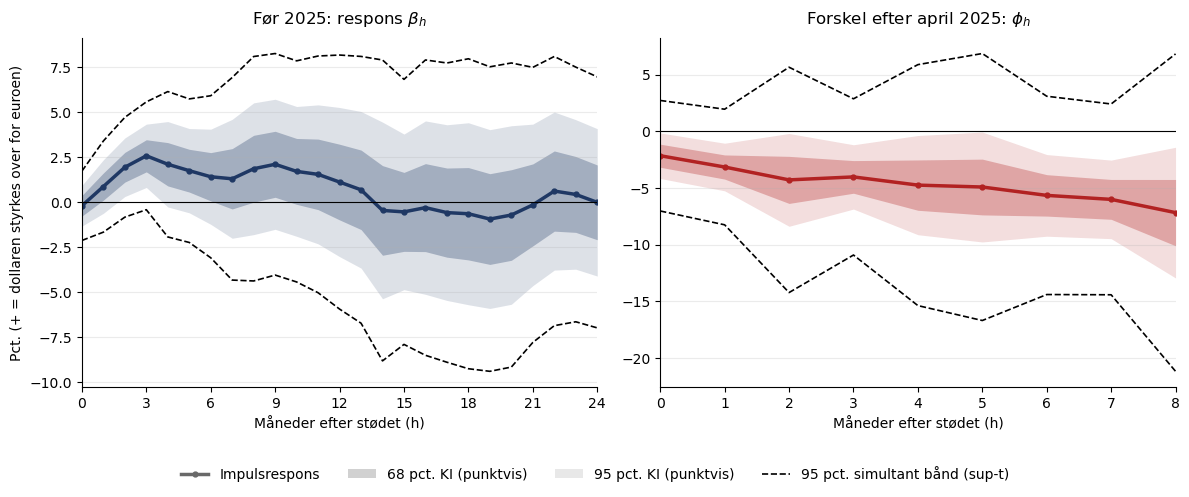

In [ ]:
# ---------- Figur: simultane (sup-t) bånd for TPU før 2025 og bruddet (EUR/USD) ----------
tpu_pre, brud = bs["TPU (før 2025)"], brud_bs["lnUSD"]
print(f"Før 2025: sup-t kritisk værdi = {tpu_pre.attrs['q_sup']:.2f}")
print(f"Bruddet:  sup-t kritisk værdi = {brud.attrs['q_sup']:.2f}, "
      f"fælles test af intet brud (h=0–{H_POST}): p = {brud.attrs['p_sup']:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, r, kol, sekol, farve, titel, H_ in [
        (ax1, tpu_pre, "coef",     "se",     BLAA, r"Før 2025: respons $\beta_h$",       24),
        (ax2, brud,    "coef_int", "se_int", ROED, r"Forskel efter april 2025: $\phi_h$", H_POST)]:
    tegn_panel(ax, r["h"], r[kol], r[sekol], farve, titel)
    ax.plot(r["h"], r["lo95_sup"], ls="--", color="black", lw=1.2)
    ax.plot(r["h"], r["hi95_sup"], ls="--", color="black", lw=1.2)
    ax.set_xlim(0, H_); ax.set_xticks(range(0, H_ + 1, 3 if H_ > 8 else 1))
ax1.set_ylabel(YL_USD)
legende(fig, punktvis=True,
        ekstra=[Line2D([0], [0], color="black", ls="--", lw=1.2, label="95 pct. simultant bånd (sup-t)")])
plt.tight_layout(rect=(0, 0.06, 1, 1))
gem_fig("lp_tpu_supt"); plt.show()

## 11. Diagnostik: er den uventede del af stødet serielt ukorreleret? (MOPM, antagelse 1)

In [ ]:
def innovation_tjek(shock, y="lnUSD", lags_liste=(1, 2, 3), controls=BASIS_KONTROLLER):
    """Ljung-Box på residualet fra en regression af stødet på lags af kontroller, Δy og stødet."""
    ud = []
    for n_lags in lags_liste:
        d = master.sort_values("month").reset_index(drop=True).copy()
        d["_dy"] = d[y].diff()
        lag_cols = []
        for v in list(controls) + ["_dy", shock]:
            for L in range(1, n_lags + 1):
                d[f"{v}_L{L}"] = d[v].shift(L)
                lag_cols.append(f"{v}_L{L}")
        sub = d[[shock] + lag_cols].dropna()
        u = sm.OLS(sub[shock], sm.add_constant(sub[lag_cols])).fit().resid
        lb  = acorr_ljungbox(u,      lags=[1, 3, 6, 12])["lb_pvalue"].values
        lb2 = acorr_ljungbox(u ** 2, lags=[1, 3, 6, 12])["lb_pvalue"].values
        ud.append({"lags": n_lags,
                   "u: LB-p (1)": lb[0], "u: LB-p (3)": lb[1],
                   "u: LB-p (6)": lb[2], "u: LB-p (12)": lb[3],
                   "u²: LB-p (12)": lb2[3], "skævhed": skew(u)})
    return pd.DataFrame(ud).set_index("lags").round(3)

for y in ["lnUSD", "hr"]:
    for s, *_ in STOED:
        print(f"{y} | {s}"); display(innovation_tjek(s, y=y))

lnUSD | lnTPU_z


,u: LB-p (1),u: LB-p (3),u: LB-p (6),u: LB-p (12),u²: LB-p (12),skævhed
lags,,,,,,
1,0.016,0.095,0.213,0.690,0.969,0.881
2,0.981,0.976,0.887,0.989,0.983,0.901
3,0.929,0.950,0.839,0.984,0.989,1.007


lnUSD | lnGPR_z


,u: LB-p (1),u: LB-p (3),u: LB-p (6),u: LB-p (12),u²: LB-p (12),skævhed
lags,,,,,,
1,0.066,0.167,0.509,0.453,0.996,1.152
2,0.994,0.983,0.924,0.857,0.926,1.151
3,0.998,1.000,0.952,0.923,0.973,1.108


lnUSD | lnGPRC_USA_z


,u: LB-p (1),u: LB-p (3),u: LB-p (6),u: LB-p (12),u²: LB-p (12),skævhed
lags,,,,,,
1,0.051,0.115,0.382,0.336,0.972,0.731
2,0.899,0.843,0.873,0.858,0.693,0.802
3,0.983,0.993,0.906,0.926,0.896,0.797


... (2 outputs left out)

hr | lnGPR_z


,u: LB-p (1),u: LB-p (3),u: LB-p (6),u: LB-p (12),u²: LB-p (12),skævhed
lags,,,,,,
1,0.069,0.161,0.518,0.381,0.991,1.174
2,0.997,0.992,0.900,0.807,0.887,1.178
3,0.989,0.996,0.930,0.860,0.946,1.172


hr | lnGPRC_USA_z


,u: LB-p (1),u: LB-p (3),u: LB-p (6),u: LB-p (12),u²: LB-p (12),skævhed
lags,,,,,,
1,0.049,0.107,0.394,0.271,0.937,0.754
2,0.901,0.906,0.872,0.829,0.551,0.826
3,0.969,0.980,0.865,0.865,0.812,0.863
